# ENG5338 CW2 Steel defect classification

**Group 5.** We compare logistic regression, RBF SVM, random forest and histogram gradient boosting on 1,941 records with 27 numeric features and seven defect classes. Normal steel is not represented.

The project targets minimum class OOF recall ≥ 0.60 and prediction P95 ≤ 20 ms for a 100-row batch. These are coursework assumptions.

**RBF SVM is the preferred development candidate, not a deployment-ready solution.** Its frozen pipeline uses median imputation, standardisation, `C=33.33333333333333`, `gamma=0.03` and balanced class weights. Pastry recall on the holdout is 18/32 = 0.5625, below the target.

 Select the **steel plates** kernel and run all cells. Project resources are located from this folder or a parent directory. Variables, parameter names and raw data fields are retained.

In [1]:
from pathlib import Path
import hashlib, json
def find_project_root(start):
    for folder in (start, *start.parents):
        if (folder/'frozen_decision.json').is_file() and (folder/'data/steel-plates-faults.csv').is_file():
            return folder
    raise FileNotFoundError('Open this notebook inside the integrated CW2 project.')

INTEGRATED_ROOT=find_project_root(Path.cwd().resolve())
FROZEN_DECISION=json.loads((INTEGRATED_ROOT/'frozen_decision.json').read_text())
FROZEN_BASE_REPS={'LogisticRegression':'LogisticRegression_09','RBF_SVC':'RBF_SVC_11',
 'RandomForest':'RandomForest_12','HistGradientBoosting':'HistGradientBoosting_07'}
FROZEN_KERNEL_REPS={'linear':'SVM_042','rbf':'SVM_049'}
assert hashlib.sha256((INTEGRATED_ROOT/'archive/frozen_RBF_SVM.joblib').read_bytes()).hexdigest()==FROZEN_DECISION['model_sha256']
assert not FROZEN_DECISION['test_metrics_used_for_this_decision']

print('Frozen before test:', FROZEN_DECISION['params'])


Frozen before test: {'kernel': 'rbf', 'C': 33.33333333333333, 'gamma': 0.03, 'class_weight': 'balanced'}


## Part A — Four-model comparison

The original 48 configurations share the same development folds. Retained representatives are reused for comparison; fresh timings do not change the frozen SVM choice.

In [2]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter, sleep
import hashlib
import importlib.metadata
import json
import os
import platform
import subprocess
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_info, threadpool_limits

SEED = 0
MIN_RECALL = 0.60
LATENCY_LIMIT_MS = 20.0
BATCH_SIZE = 100
PREDICTION_REPEATS = 100
FIT_REPEATS = 5
DATA_SHA256 = '9e9bfebd2ea8bf84f5264325fadace2194387991183cb20d52075ef72e2c858e'
PROJECT = INTEGRATED_ROOT / 'base'
DATA_PATH = INTEGRATED_ROOT / 'data' / 'steel-plates-faults.csv'
if not DATA_PATH.is_file():
    raise FileNotFoundError('Missing project data/steel-plates-faults.csv.')
RUN_DIR = PROJECT / 'results' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
FIG_DIR = RUN_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=False)
warnings.filterwarnings('error', category=ConvergenceWarning)
sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 20)
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160})

def json_default(x):
    if isinstance(x, Path): return str(x)
    if isinstance(x, np.generic): return x.item()
    if isinstance(x, np.ndarray): return x.tolist()
    raise TypeError(type(x).__name__)

def save_json(value, filename):
    (RUN_DIR / filename).write_text(json.dumps(value, ensure_ascii=False, indent=2,
        default=json_default, allow_nan=False), encoding='utf-8')

def save_table(frame, filename, index=False):
    frame.to_csv(RUN_DIR / filename, index=index, encoding='utf-8-sig')

def figure(fig, filename):
    fig.savefig(FIG_DIR / filename, bbox_inches='tight')
    plt.show()
    plt.close(fig)

packages = ['numpy','pandas','scipy','scikit-learn','matplotlib','seaborn','psutil',
            'joblib','threadpoolctl','nbformat','nbclient','nbconvert','ipykernel']
runtime = {'python': sys.version, 'executable': sys.executable, 'os': platform.platform(),
    'processor': platform.processor(), 'physical_cpus': psutil.cpu_count(logical=False),
    'logical_cpus': psutil.cpu_count(), 'ram_gib': psutil.virtual_memory().total / 1024**3,
    'versions': {p:importlib.metadata.version(p) for p in packages},
    'thread_policy': 'Sequential CV; n_jobs=1; BLAS/OpenMP limited to 1 during fits and prediction.',
    'initial_threadpools': threadpool_info()}
save_json(runtime, 'environment.json')
save_json({'seed': SEED, 'test_size': .2, 'folds': 5, 'min_class_recall': MIN_RECALL,
    'batch_rows': BATCH_SIZE, 'prediction_p95_limit_ms': LATENCY_LIMIT_MS,
    'prediction_repeats': PREDICTION_REPEATS, 'fit_repeats': FIT_REPEATS,
    'holdout_previously_used_in_cw1': True, 'test_evaluation_count': 0}, 'protocol.json')
print('Run:', RUN_DIR)
display(pd.Series(runtime['versions'], name='version').to_frame())


Run: C:\Users\lei\Documents\ChatGPT\钢铁数据集\CW2_integrated_20261114\base\results\20261115_140342_461965


,version
numpy,2.4.6
pandas,2.3.3
scipy,1.17.1
scikit-learn,1.7.2
matplotlib,3.11.2
seaborn,0.13.2
psutil,7.2.2
joblib,1.6.0
threadpoolctl,3.7.0
nbformat,5.11.1


## 1. Data and split

The data contain 27 numeric features and seven defect classes. A stratified 80/20 split gives 1,552 development rows and 389 holdout rows, with seed 0. Missing values, duplicate records and feature scales are checked. Detailed exploration uses development data only; extreme values and correlated features are retained.

,all,train,test
bumps,402,321,81
dirtiness,55,44,11
k_scatch,391,313,78
other_faults,673,538,135
pastry,158,126,32
stains,72,58,14
z_scratch,190,152,38


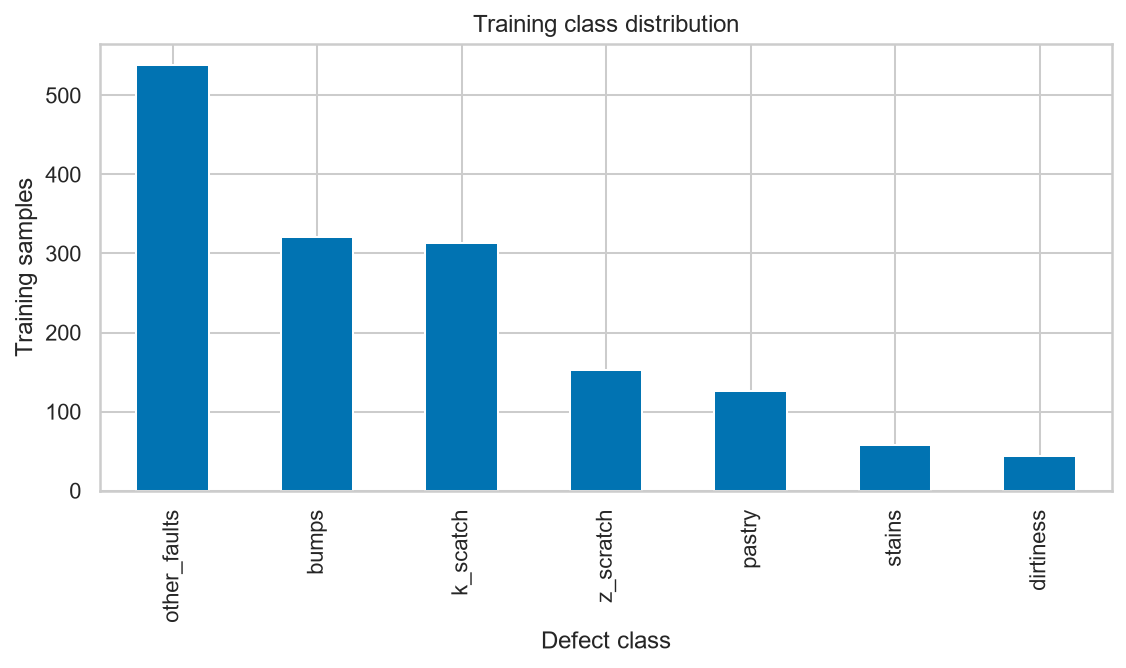

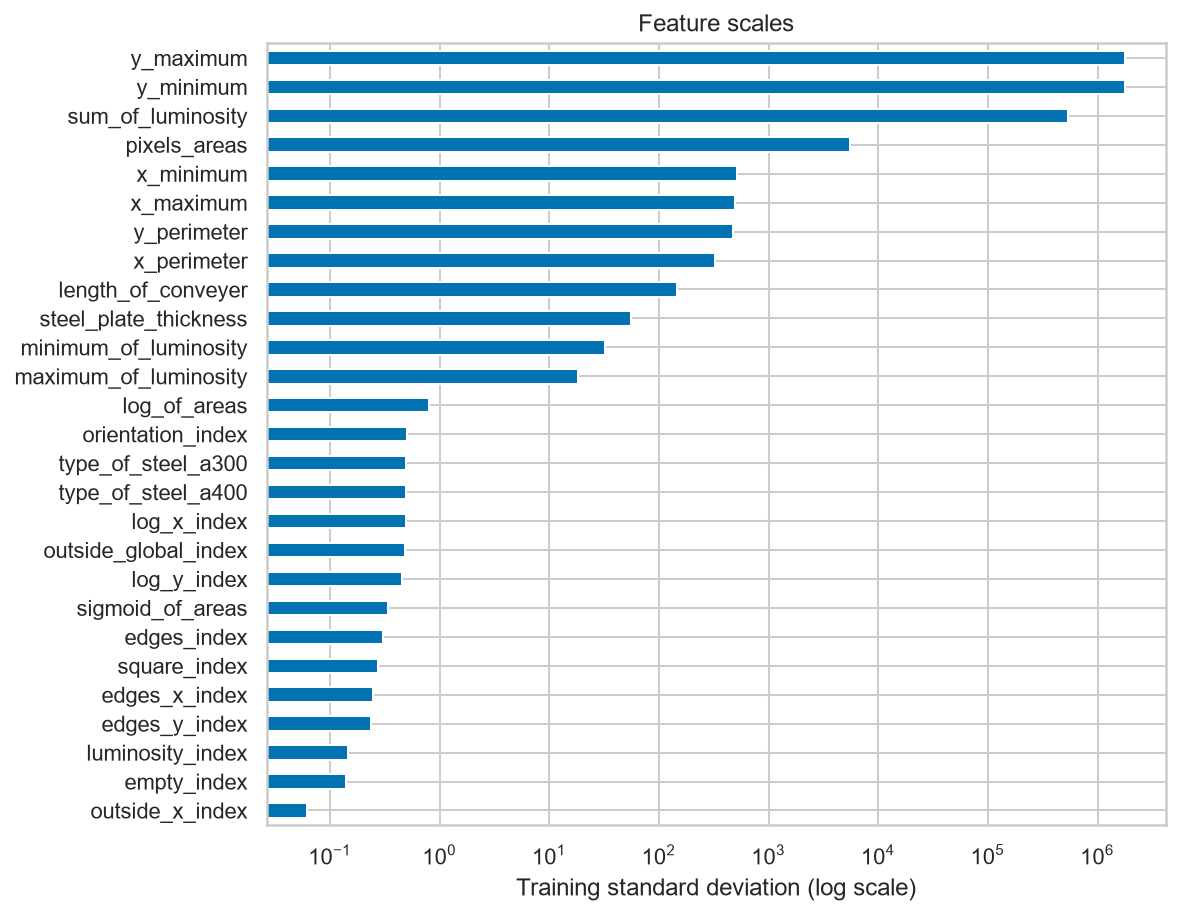

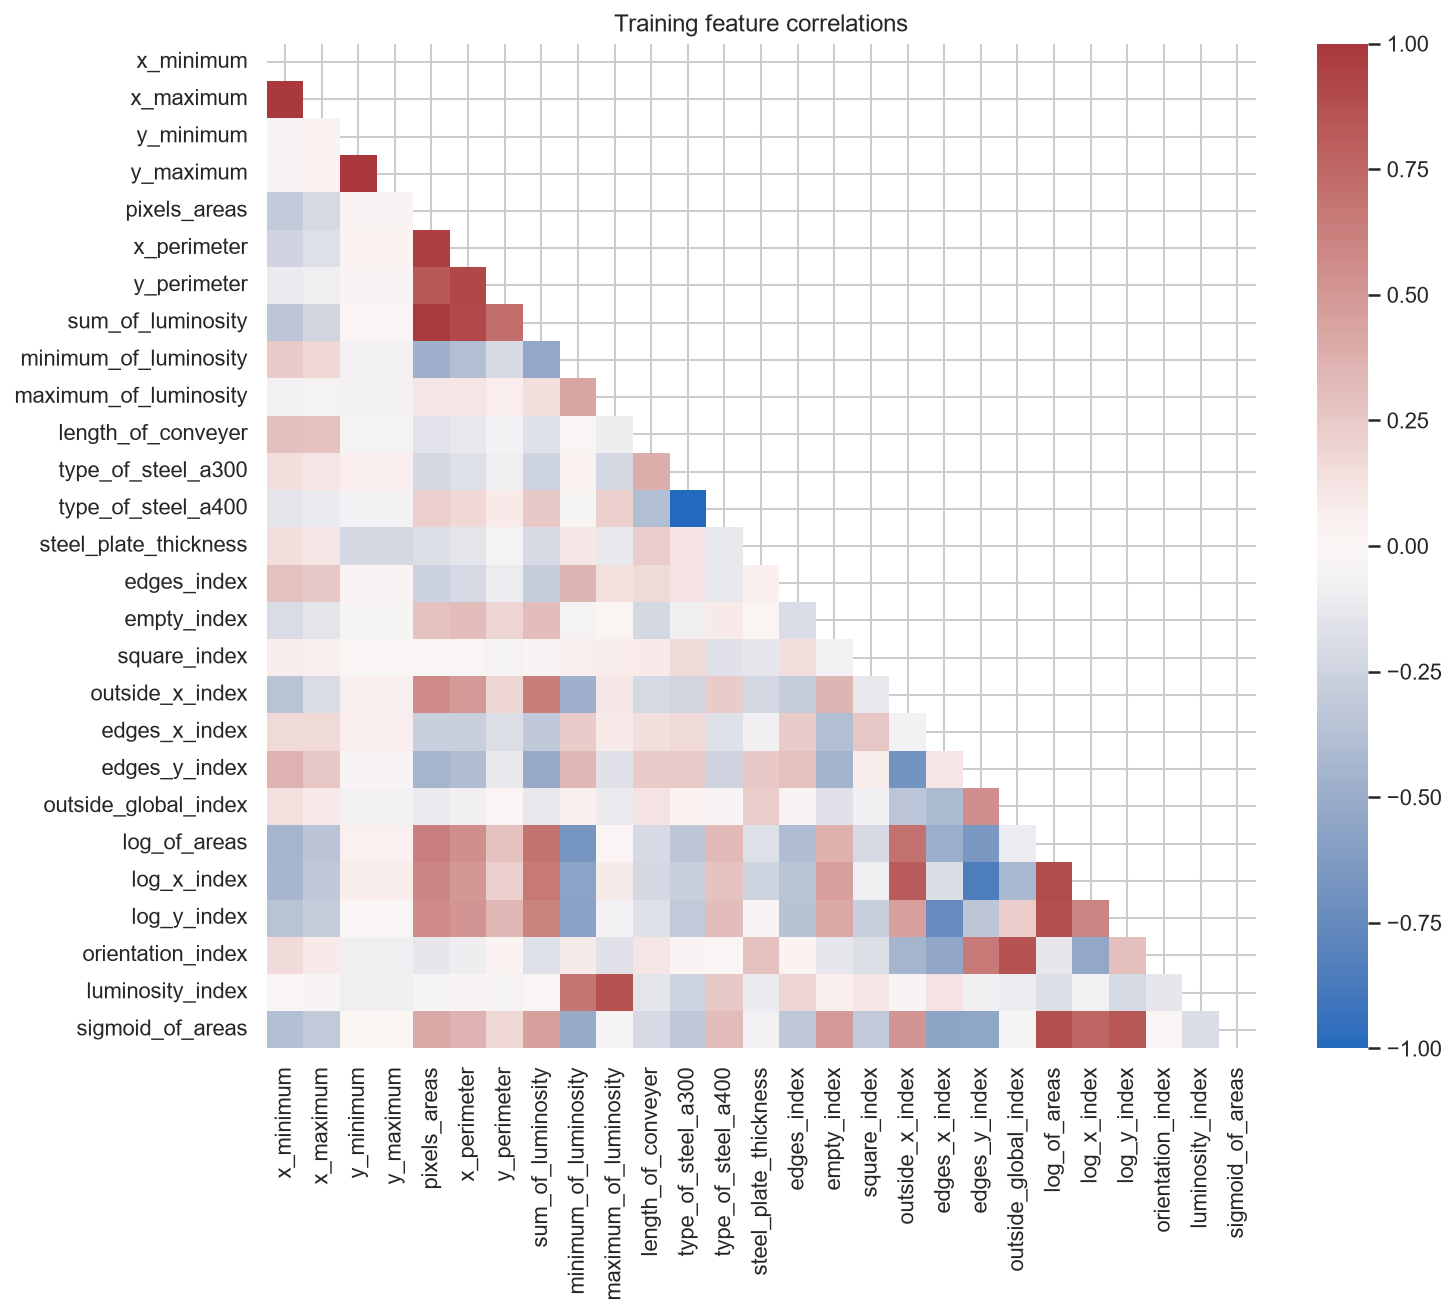

In [3]:
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == DATA_SHA256
df = pd.read_csv(DATA_PATH)
assert df.shape == (1941, 28) and 'fault_type' in df
X = df.drop(columns='fault_type')
y = df['fault_type']
assert all(pd.api.types.is_numeric_dtype(t) for t in X.dtypes)
assert np.isfinite(X.to_numpy(dtype=float)[~X.isna().to_numpy()]).all()
assert not X.duplicated().any(), 'Duplicate feature records require a grouped split review.'
assert y.notna().all() and y.nunique() == 7
classes = sorted(y.unique())
audit = {'rows':len(df), 'features':X.shape[1], 'classes':len(classes),
         'missing_feature_cells':int(X.isna().sum().sum()), 'duplicate_rows':int(df.duplicated().sum())}
save_json({'path':DATA_PATH, 'sha256':DATA_SHA256, **audit}, 'dataset_audit.json')
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=.2,random_state=SEED,stratify=y)
assert len(X_train) == 1552 and len(X_test) == 389
assert set(X_train.index).isdisjoint(X_test.index)
split = pd.DataFrame({'row_id':df.index,'csv_line':df.index+2,'split':'train'})
split.loc[X_test.index,'split'] = 'test'
save_table(split, 'split_membership.csv')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train,y_train))
fold_ids = np.full(len(X_train),-1)
for fold,(fit,val) in enumerate(folds):
    assert not set(fit).intersection(val)
    fold_ids[val] = fold+1
save_table(pd.DataFrame({'row_id':X_train.index,'validation_fold':fold_ids}), 'cv_fold_membership.csv')
save_json(audit, 'audit.json')
counts = pd.DataFrame({'all':y.value_counts(),'train':y_train.value_counts(),'test':y_test.value_counts()}).loc[classes]
save_table(counts.rename_axis('class').reset_index(), 'class_counts.csv')
display(counts)
fig,ax = plt.subplots(figsize=(9,4))
y_train.value_counts().plot.bar(ax=ax)
ax.set(xlabel='Defect class',ylabel='Training samples',title='Training class distribution')
figure(fig,'01_class_distribution.png')
stats = X_train.describe().T
save_table(stats.rename_axis('feature').reset_index(), 'feature_statistics_train.csv')
fig,ax=plt.subplots(figsize=(8,7))
X_train.std().sort_values().plot.barh(ax=ax)
ax.set(xscale='log',xlabel='Training standard deviation (log scale)',title='Feature scales')
figure(fig,'02_feature_scales.png')
corr=X_train.corr()
fig,ax=plt.subplots(figsize=(11,9))
sns.heatmap(corr,mask=np.triu(np.ones_like(corr,dtype=bool)),vmin=-1,vmax=1,cmap='vlag',ax=ax)
ax.set_title('Training feature correlations')
figure(fig,'03_correlations.png')
correlation_pairs=[{'feature_1':a,'feature_2':b,'r':float(corr.loc[a,b])}
    for i,a in enumerate(corr.columns) for b in corr.columns[i+1:] if abs(corr.loc[a,b])>=.9]
save_table(pd.DataFrame(correlation_pairs),'high_correlations_train.csv')
continuous=X_train.loc[:,X_train.nunique()>2]
q1,q3=continuous.quantile(.25),continuous.quantile(.75)
iqr=q3-q1
flags=(continuous.lt(q1-1.5*iqr)|continuous.gt(q3+1.5*iqr)).sum()
save_table(flags.rename('flagged_count').rename_axis('feature').reset_index(),'iqr_flags_train.csv')


## 2. Pipelines and parameters

Logistic regression and SVM use median imputation, standardisation and a classifier; tree models omit scaling. Preprocessing is fitted within each training fold. Each family has 12 configurations, ranked by macro F1 with class OOF recall checks. Boosting uses 200 iterations, minimum leaf size 10 and L2=1, without early stopping.

In [4]:
grids = {
 'LogisticRegression': {'C':[.01,.1,1,10,100,1000], 'class_weight':[None,'balanced']},
 'RBF_SVC': {'C':[.1,1,10], 'gamma':['scale',.01], 'class_weight':[None,'balanced']},
 'RandomForest': {'max_depth':[8,16,None], 'min_samples_leaf':[1,5], 'class_weight':[None,'balanced']},
 'HistGradientBoosting': {'learning_rate':[.05,.1], 'max_leaf_nodes':[7,15,31], 'class_weight':[None,'balanced']},
}

def make_pipeline(family, params):
    if family == 'LogisticRegression':
        model=LogisticRegression(penalty='l2',solver='lbfgs',max_iter=5000,random_state=SEED,**params)
    elif family == 'RBF_SVC':
        model=SVC(kernel='rbf',probability=False,**params)
    elif family == 'RandomForest':
        model=RandomForestClassifier(n_estimators=300,max_features='sqrt',n_jobs=1,random_state=SEED,**params)
    elif family == 'HistGradientBoosting':
        model=HistGradientBoostingClassifier(max_iter=200,min_samples_leaf=10,l2_regularization=1,
            early_stopping=False,random_state=SEED,**params)
    else: raise ValueError(family)
    steps=[('imputer',SimpleImputer(strategy='median'))]
    if family in ('LogisticRegression','RBF_SVC'): steps.append(('scaler',StandardScaler()))
    return Pipeline(steps+[('model',model)])

def check_preprocessing(pipe, train):
    np.testing.assert_allclose(pipe['imputer'].statistics_,train.median().to_numpy())
    if 'scaler' in pipe.named_steps:
        filled=pipe['imputer'].transform(train)
        np.testing.assert_allclose(pipe['scaler'].mean_,np.mean(filled,axis=0),rtol=1e-9,atol=1e-9)
        assert np.all(np.asarray(pipe['scaler'].n_samples_seen_) == len(train))

def class_report(truth,prediction):
    return pd.DataFrame(classification_report(truth,prediction,labels=classes,
        output_dict=True,zero_division=0)).T.loc[classes]

candidates=[]
for family,grid in grids.items():
    assert len(list(ParameterGrid(grid))) == 12
    for num,params in enumerate(ParameterGrid(grid),1):
        candidates.append({'candidate_id':f'{family}_{num:02d}','family':family,'params':params})
save_json({'parameter_grids':grids,'candidate_count':len(candidates),
    'fixed_settings':{'RF_trees':300,'HGB_max_iter':200,'HGB_min_samples_leaf':10,
                      'HGB_l2_regularization':1,'HGB_early_stopping':False}},'search_space.json')


## 3. Five-fold validation

All configurations use the same five folds. Each development row receives one OOF prediction. Training and validation F1 indicate overfitting; non-converged configurations are excluded. Fold standard deviation describes variation.

In [5]:
fold_rows=[]
candidate_rows=[]
oof_frames=[]
fit_failures=[]
search_cost=[]
for family in grids:
    family_start=perf_counter()
    for candidate in [c for c in candidates if c['family']==family]:
        cid,params=candidate['candidate_id'],candidate['params']
        oof=np.empty(len(X_train),dtype=object)
        seen=np.zeros(len(X_train),dtype=int)
        local=[]
        start=perf_counter()
        try:
            for fold,(fit_idx,val_idx) in enumerate(folds,1):
                pipe=make_pipeline(family,params)
                with threadpool_limits(limits=1):
                    t=perf_counter()
                    pipe.fit(X_train.iloc[fit_idx],y_train.iloc[fit_idx])
                    fit_seconds=perf_counter()-t
                    check_preprocessing(pipe,X_train.iloc[fit_idx])
                    train_pred=pipe.predict(X_train.iloc[fit_idx])
                    t=perf_counter()
                    val_pred=pipe.predict(X_train.iloc[val_idx])
                    predict_seconds=perf_counter()-t
                oof[val_idx]=val_pred
                seen[val_idx]+=1
                row={'candidate_id':cid,'family':family,'fold':fold,'fit_rows':len(fit_idx),
                    'validation_rows':len(val_idx),'train_macro_f1':f1_score(y_train.iloc[fit_idx],train_pred,average='macro'),
                    'validation_macro_f1':f1_score(y_train.iloc[val_idx],val_pred,average='macro'),
                    'validation_accuracy':accuracy_score(y_train.iloc[val_idx],val_pred),
                    'fit_seconds':fit_seconds,'validation_predict_seconds':predict_seconds}
                for label,recall in class_report(y_train.iloc[val_idx],val_pred)['recall'].items():
                    row['recall_'+label]=float(recall)
                local.append(row)
            assert np.all(seen==1)
            report=class_report(y_train,oof)
            train_mean=float(np.mean([r['train_macro_f1'] for r in local]))
            val_mean=float(np.mean([r['validation_macro_f1'] for r in local]))
            row={'candidate_id':cid,'family':family,'params':json.dumps(params,sort_keys=True),
                'train_macro_f1':train_mean,'validation_macro_f1':val_mean,
                'validation_macro_f1_std':float(np.std([r['validation_macro_f1'] for r in local],ddof=1)),
                'validation_accuracy':float(np.mean([r['validation_accuracy'] for r in local])),
                'train_validation_gap':train_mean-val_mean,'oof_macro_f1':f1_score(y_train,oof,average='macro'),
                'oof_min_class_recall':float(report['recall'].min()),
                'quality_pass':bool(report['recall'].min()>=MIN_RECALL),
                'mean_fold_fit_seconds':float(np.mean([r['fit_seconds'] for r in local])),
                'candidate_wall_seconds':perf_counter()-start}
            for label,recall in report['recall'].items(): row['oof_recall_'+label]=float(recall)
            candidate_rows.append(row)
            fold_rows.extend(local)
            oof_frames.append(pd.DataFrame({'candidate_id':cid,'family':family,'row_id':X_train.index,
                'validation_fold':fold_ids,'truth':y_train.to_numpy(),'prediction':oof}))
            print(f'{cid}: CV F1={val_mean:.4f}; min OOF recall={row["oof_min_class_recall"]:.3f}',flush=True)
        except Exception as exc:
            fit_failures.append({'candidate_id':cid,'family':family,'error_type':type(exc).__name__,'error':str(exc)})
            print(f'{cid}: FAILED {type(exc).__name__}: {exc}',flush=True)
        save_table(pd.DataFrame(candidate_rows),'cv_candidates.csv')
        save_table(pd.DataFrame(fold_rows),'cv_folds.csv')
        if oof_frames: save_table(pd.concat(oof_frames,ignore_index=True),'oof_predictions.csv')
        save_json(fit_failures,'fit_failures.json')
    search_cost.append({'family':family,'search_wall_seconds_including_checks':perf_counter()-family_start})
    save_table(pd.DataFrame(search_cost),'search_cost.csv')
cv_results=pd.DataFrame(candidate_rows)
assert set(cv_results['family'])==set(grids), 'Each family must have at least one complete candidate.'
assert len(fold_rows)==len(candidate_rows)*5
display(cv_results.sort_values('validation_macro_f1',ascending=False).head(12))


LogisticRegression_01: CV f1-score=0.5339; min OOF recall=0.000
LogisticRegression_02: CV f1-score=0.5801; min OOF recall=0.288
LogisticRegression_03: CV f1-score=0.7117; min OOF recall=0.460
LogisticRegression_04: CV f1-score=0.6443; min OOF recall=0.375
LogisticRegression_05: CV f1-score=0.7136; min OOF recall=0.500
LogisticRegression_06: CV f1-score=0.6541; min OOF recall=0.387
LogisticRegression_07: CV f1-score=0.7137; min OOF recall=0.523
LogisticRegression_08: CV f1-score=0.6528; min OOF recall=0.385
LogisticRegression_09: CV f1-score=0.7144; min OOF recall=0.523
LogisticRegression_10: CV f1-score=0.6573; min OOF recall=0.392
LogisticRegression_11: CV f1-score=0.7046; min OOF recall=0.523
LogisticRegression_12: CV f1-score=0.6653; min OOF recall=0.398
RBF_SVC_01: CV f1-score=0.4436; min OOF recall=0.000
RBF_SVC_02: CV f1-score=0.2156; min OOF recall=0.000
RBF_SVC_03: CV f1-score=0.6527; min OOF recall=0.433
RBF_SVC_04: CV f1-score=0.5518; min OOF recall=0.221
RBF_SVC_05: CV f1-sc

,candidate_id,family,params,train_macro_f1,validation_macro_f1,validation_macro_f1_std,validation_accuracy,train_validation_gap,oof_macro_f1,oof_min_class_recall,quality_pass,mean_fold_fit_seconds,candidate_wall_seconds,oof_recall_bumps,oof_recall_dirtiness,oof_recall_k_scatch,oof_recall_other_faults,oof_recall_pastry,oof_recall_stains,oof_recall_z_scratch
45,HistGradientBoosting_10,HistGradientBoosting,"{""class_weight"": ""balanced"", ""learning_rate"": ...",0.9997,0.8086,0.0434,0.7867,0.1911,0.8092,0.6032,True,1.1045,6.3922,0.7009,0.8182,0.9681,0.7100,0.6032,0.9310,0.9539
47,HistGradientBoosting_12,HistGradientBoosting,"{""class_weight"": ""balanced"", ""learning_rate"": ...",1.0000,0.8061,0.0466,0.7860,0.1939,0.8068,0.6111,True,2.5696,13.9960,0.6822,0.8182,0.9585,0.7249,0.6111,0.9310,0.9474
43,HistGradientBoosting_08,HistGradientBoosting,"{""class_weight"": ""balanced"", ""learning_rate"": ...",1.0000,0.8049,0.0461,0.7809,0.1951,0.8054,0.5952,False,1.5200,8.5397,0.7009,0.8182,0.9489,0.7026,0.5952,0.9310,0.9671
42,HistGradientBoosting_07,HistGradientBoosting,"{""class_weight"": ""balanced"", ""learning_rate"": ...",0.9813,0.8043,0.0391,0.7809,0.1770,0.8051,0.6349,True,0.7459,4.4361,0.7227,0.8182,0.9617,0.6710,0.6349,0.9310,0.9737
46,HistGradientBoosting_11,HistGradientBoosting,"{""class_weight"": ""balanced"", ""learning_rate"": ...",1.0000,0.8043,0.0424,0.7867,0.1957,0.8049,0.5635,False,1.9014,10.5373,0.6947,0.8182,0.9585,0.7286,0.5635,0.9310,0.9539
44,HistGradientBoosting_09,HistGradientBoosting,"{""class_weight"": ""balanced"", ""learning_rate"": ...",1.0000,0.8039,0.0518,0.7835,0.1961,0.8045,0.5952,False,2.3207,12.6502,0.6854,0.8182,0.9617,0.7156,0.5952,0.9310,0.9539
37,HistGradientBoosting_02,HistGradientBoosting,"{""class_weight"": null, ""learning_rate"": 0.05, ...",1.0000,0.8013,0.0443,0.7822,0.1987,0.8022,0.5079,False,1.1249,6.4166,0.6573,0.7500,0.9553,0.7602,0.5079,0.9310,0.9474
38,HistGradientBoosting_03,HistGradientBoosting,"{""class_weight"": null, ""learning_rate"": 0.05, ...",1.0000,0.8013,0.0463,0.7893,0.1987,0.8019,0.5317,False,1.5687,8.7503,0.6791,0.7500,0.9617,0.7639,0.5317,0.9138,0.9342
40,HistGradientBoosting_05,HistGradientBoosting,"{""class_weight"": null, ""learning_rate"": 0.1, ""...",1.0000,0.7998,0.0428,0.7828,0.2002,0.7998,0.5079,False,1.1308,6.4455,0.6449,0.7500,0.9553,0.7677,0.5079,0.9310,0.9539
41,HistGradientBoosting_06,HistGradientBoosting,"{""class_weight"": null, ""learning_rate"": 0.1, ""...",1.0000,0.7985,0.0458,0.7860,0.2015,0.7988,0.5317,False,1.5499,8.6486,0.6604,0.7500,0.9585,0.7695,0.5317,0.8966,0.9342


## 4. Representative comparison

Timing and learning curves use the retained representatives. The automatic ranking below describes this run only; it is not the final frozen SVM decision.

In [6]:
def latency_measure(pipe,batch):
    assert len(batch)==BATCH_SIZE
    with threadpool_limits(limits=1):
        for _ in range(5): pipe.predict(batch)
        values=[]
        for _ in range(PREDICTION_REPEATS):
            t=perf_counter()
            pipe.predict(batch)
            values.append((perf_counter()-t)*1000)
    return np.asarray(values)

batch_positions=np.random.default_rng(SEED).choice(len(X_train),BATCH_SIZE,replace=False)
development_batch=X_train.iloc[batch_positions]
save_table(pd.DataFrame({'row_id':development_batch.index}),'latency_batch_rows.csv')
timing_checks=[]
latency_samples=[]
representatives=[]
representative_models={}
params_by_id={c['candidate_id']:c['params'] for c in candidates}
for family in grids:
    pool=cv_results[cv_results.family==family].copy()
    pool['recall_deficit']=(MIN_RECALL-pool.oof_min_class_recall).clip(lower=0)
    ordered=pool.loc[pool.candidate_id.eq(FROZEN_BASE_REPS[family])].copy()
    assert len(ordered)==1
    evaluated=[]
    saved_models={}
    for _,row in ordered.iterrows():
        cid=row['candidate_id']
        pipe=make_pipeline(family,params_by_id[cid])
        with threadpool_limits(limits=1):
            t=perf_counter()
            pipe.fit(X_train,y_train)
            selection_fit_seconds=perf_counter()-t
            check_preprocessing(pipe,X_train)
        samples=latency_measure(pipe,development_batch)
        result=row.to_dict()
        result.update({'prediction_median_ms':float(np.median(samples)),
            'prediction_p95_ms':float(np.quantile(samples,.95)),
            'selection_fit_seconds':selection_fit_seconds})
        result['latency_pass']=bool(result['prediction_p95_ms']<=LATENCY_LIMIT_MS)
        result['feasible']=bool(result['quality_pass'] and result['latency_pass'])
        result['constraint_violation']=float(result['recall_deficit']+max(0,result['prediction_p95_ms']/LATENCY_LIMIT_MS-1))
        timing_checks.append(result)
        latency_samples.extend({'candidate_id':cid,'repeat':i+1,'predict_100_ms':float(v)} for i,v in enumerate(samples))
        evaluated.append(result)
        saved_models[cid]=pipe
        print(f'{cid}: P95={result["prediction_p95_ms"]:.3f} ms; feasible={result["feasible"]}',flush=True)
        if result['feasible']: break
    eligible=[r for r in evaluated if r['feasible']]
    chosen=(eligible[0] if eligible else sorted(evaluated,key=lambda r:(r['constraint_violation'],-r['validation_macro_f1'],r['candidate_id']))[0])
    representatives.append(chosen)
    representative_models[family]=saved_models[chosen['candidate_id']]
    save_table(pd.DataFrame(timing_checks),'constraint_checks.csv')
    save_table(pd.DataFrame(latency_samples),'prediction_timing_raw.csv')

comparison=pd.DataFrame(representatives)
eligible=comparison[comparison.feasible]
if len(eligible):
    recommendation=eligible.sort_values(['validation_macro_f1','prediction_p95_ms','mean_fold_fit_seconds','candidate_id'],ascending=[False,True,True,True]).iloc[0]
    selection_status='development_constraints_met'
else:
    recommendation=comparison.sort_values(['constraint_violation','validation_macro_f1','prediction_p95_ms','candidate_id'],ascending=[True,False,True,True]).iloc[0]
    selection_status='NO_FEASIBLE_MODEL_closest_reference_only'
selected_family=str(recommendation['family'])
selected_id=str(recommendation['candidate_id'])
selection={'status':selection_status,'family':selected_family,'candidate_id':selected_id,
    'params':params_by_id[selected_id],'validation_macro_f1':float(recommendation.validation_macro_f1),
    'oof_min_class_recall':float(recommendation.oof_min_class_recall),
    'development_prediction_p95_ms':float(recommendation.prediction_p95_ms),
    'locked_at_utc':datetime.now(timezone.utc).isoformat(),'test_metrics_used_for_selection':False}
save_json(selection,'selection_locked.json')
save_table(comparison,'model_comparison.csv')
display(comparison[['family','validation_macro_f1','validation_macro_f1_std','oof_min_class_recall','prediction_p95_ms','feasible']])
print('Part A automatic ranking (descriptive):',selection)


LogisticRegression_09: P95=1.027 ms; feasible=False
RBF_SVC_11: P95=8.761 ms; feasible=True
RandomForest_12: P95=15.763 ms; feasible=True
HistGradientBoosting_07: P95=18.993 ms; feasible=True


,family,validation_macro_f1,validation_macro_f1_std,oof_min_class_recall,prediction_p95_ms,feasible
0,LogisticRegression,0.7144,0.0280,0.5227,1.0272,False
1,RBF_SVC,0.7732,0.0267,0.6059,8.7612,True
2,RandomForest,0.7722,0.0407,0.6097,15.7629,True
3,HistGradientBoosting,0.8043,0.0391,0.6349,18.9934,True


Part A automatic ranking (descriptive): {'status': 'development_constraints_met', 'family': 'HistGradientBoosting', 'candidate_id': 'HistGradientBoosting_07', 'params': {'class_weight': 'balanced', 'learning_rate': 0.05, 'max_leaf_nodes': 7}, 'validation_macro_f1': 0.8043050620219375, 'oof_min_class_recall': 0.6349206349206349, 'development_prediction_p95_ms': 18.99340000027223, 'locked_at_utc': '2026-11-15T14:06:31.155771+00:00', 'test_metrics_used_for_selection': False}


## 5. Model comparison

Compare training and validation macro F1, class OOF recall and prediction time for the four representatives. The SVM supplement follows in Part B.

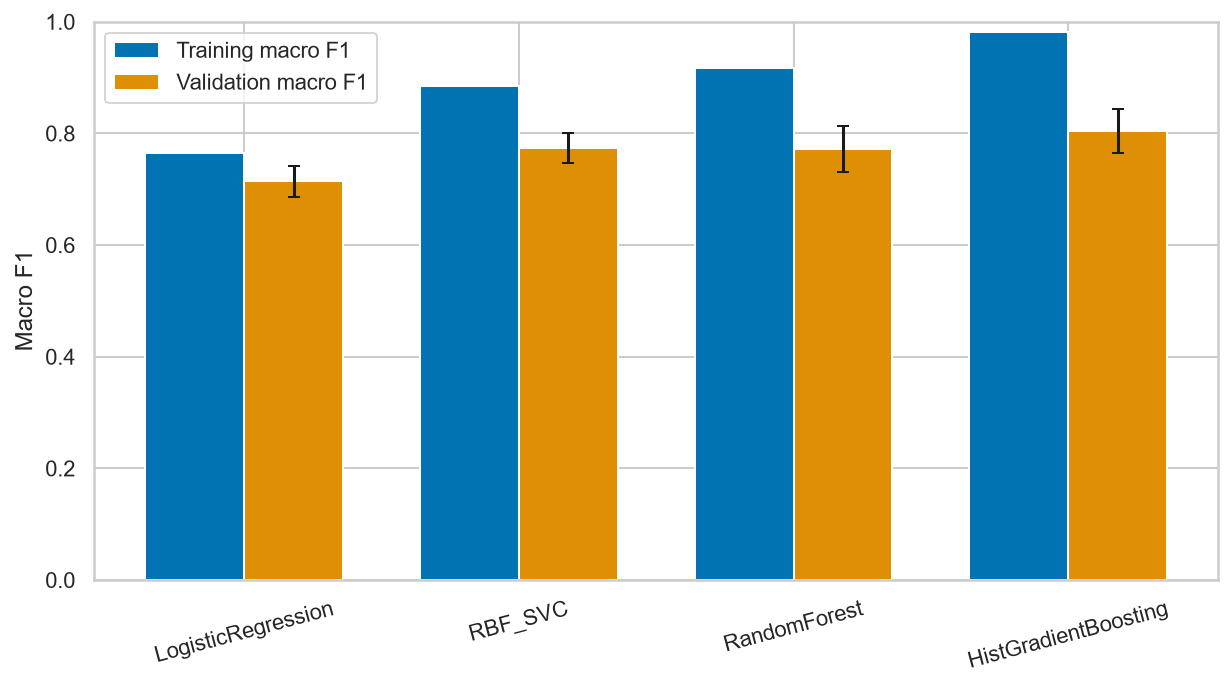

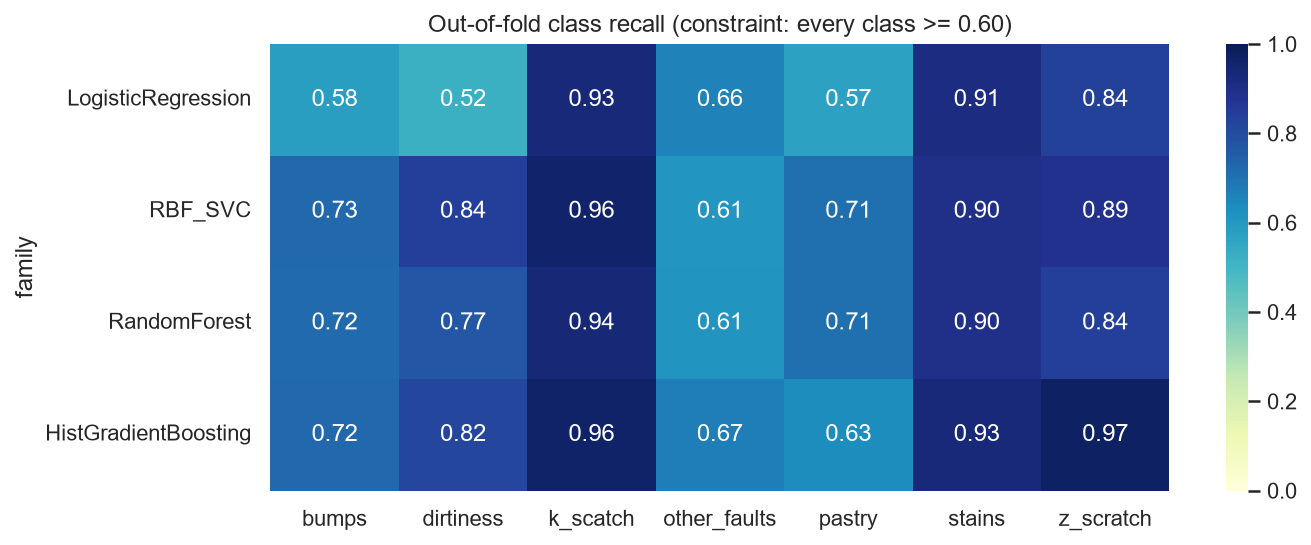

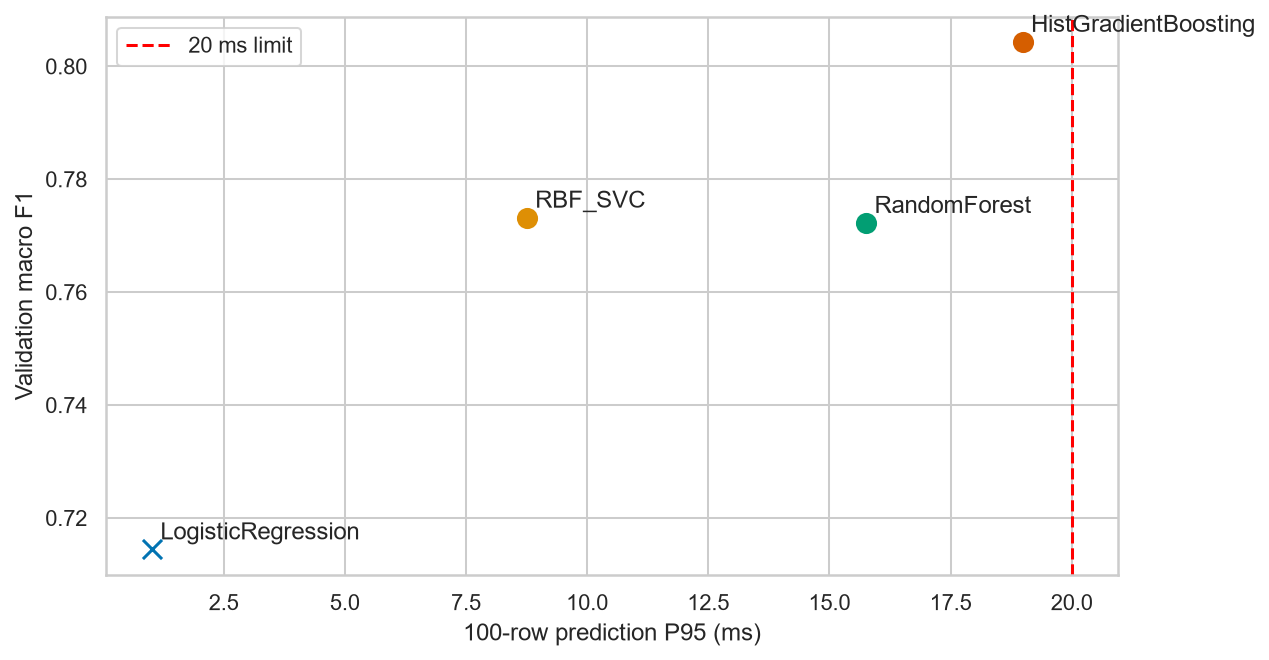

In [7]:
fig,ax=plt.subplots(figsize=(10,5))
positions=np.arange(len(comparison))
ax.bar(positions-.18,comparison.train_macro_f1,.36,label='Training macro F1')
ax.bar(positions+.18,comparison.validation_macro_f1,.36,yerr=comparison.validation_macro_f1_std,capsize=3,label='Validation macro F1')
ax.set(xticks=positions,xticklabels=comparison.family,ylim=(0,1),ylabel='Macro F1')
ax.tick_params(axis='x',rotation=15)
ax.legend()
figure(fig,'04_train_validation_f1.png')
recalls=comparison.set_index('family')[[f'oof_recall_{c}' for c in classes]]
recalls.columns=classes
fig,ax=plt.subplots(figsize=(10,4))
sns.heatmap(recalls,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='YlGnBu',ax=ax)
ax.set_title('Out-of-fold class recall (constraint: every class >= 0.60)')
figure(fig,'05_oof_class_recall.png')
fig,ax=plt.subplots(figsize=(9,5))
for _,r in comparison.iterrows():
    ax.scatter(r.prediction_p95_ms,r.validation_macro_f1,s=90,marker='o' if r.feasible else 'x')
    ax.annotate(r.family,(r.prediction_p95_ms,r.validation_macro_f1),xytext=(4,5),textcoords='offset points')
ax.axvline(LATENCY_LIMIT_MS,color='red',linestyle='--',label='20 ms limit')
ax.set(xlabel='100-row prediction P95 (ms)',ylabel='Validation macro F1')
ax.legend()
figure(fig,'06_quality_latency_tradeoff.png')


## 6. Training size and resources

Reserve 20% of development data for internal validation. Compare nested subsets containing 25%, 50%, 75% and 100% of the remaining pool, repeated five times. This validation data informed tuning, so learning curves are diagnostic only. Full-fit timing is repeated five times. Model size uses joblib file size; RSS is sampled about every 1 ms and may miss brief peaks.

Learning curves repeat 1 / 5
Learning curves repeat 2 / 5
Learning curves repeat 3 / 5
Learning curves repeat 4 / 5
Learning curves repeat 5 / 5


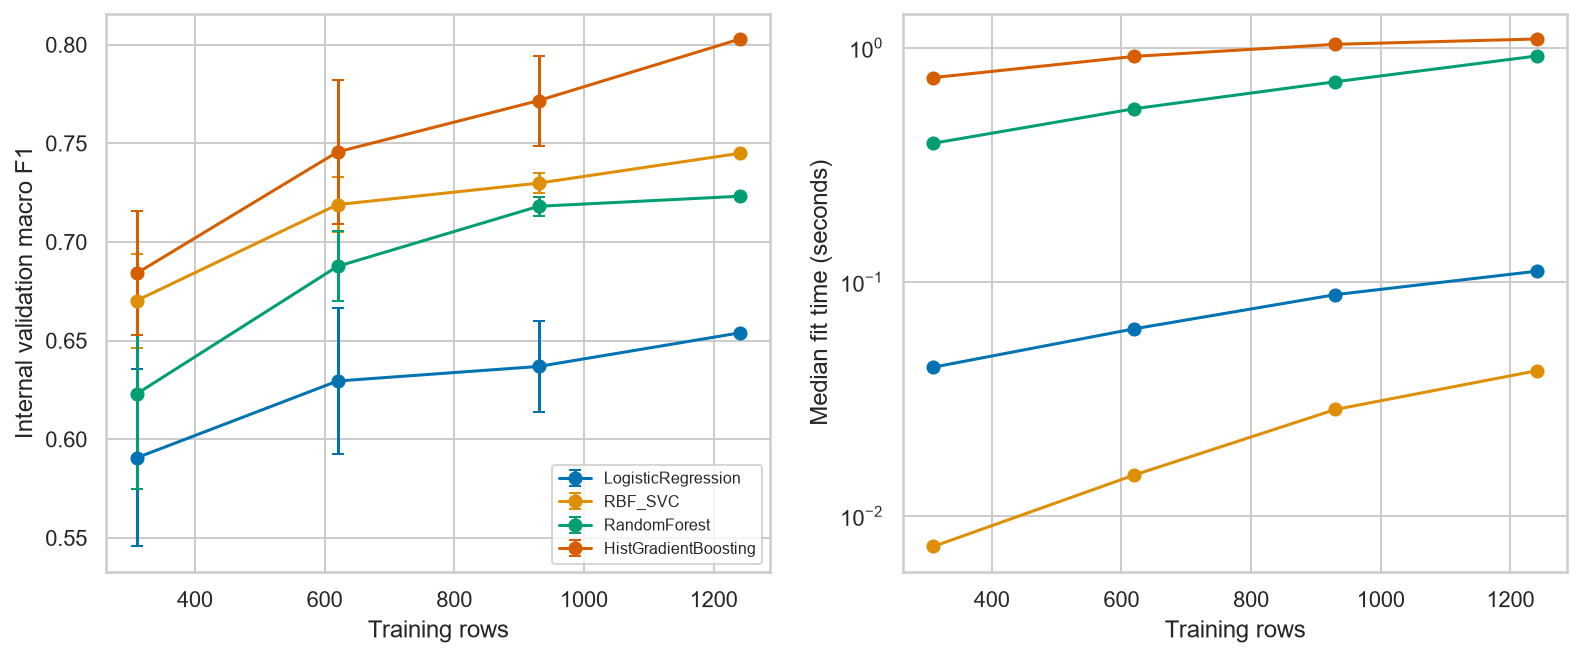

In [8]:
pool_X,learning_X,pool_y,learning_y=train_test_split(X_train,y_train,test_size=.2,stratify=y_train,random_state=SEED)
fractions=[.25,.5,.75,1.0]
subset_records=[]
learning_rows=[]
for repeat in range(5):
    nested={1.0:np.arange(len(pool_X))}
    current=nested[1.0]
    for fraction in [.75,.5,.25]:
        size=int(np.floor(len(pool_X)*fraction))
        chosen,_=train_test_split(current,train_size=size,stratify=pool_y.iloc[current],random_state=SEED+repeat)
        nested[fraction]=np.sort(chosen)
        current=nested[fraction]
    for fraction in fractions:
        idx=nested[fraction]
        subset_records.extend({'repeat':repeat+1,'fraction':fraction,'row_id':int(r)} for r in pool_X.iloc[idx].index)
        for _,r in comparison.iterrows():
            pipe=make_pipeline(r.family,params_by_id[r.candidate_id])
            with threadpool_limits(limits=1):
                t=perf_counter()
                pipe.fit(pool_X.iloc[idx],pool_y.iloc[idx])
                seconds=perf_counter()-t
                check_preprocessing(pipe,pool_X.iloc[idx])
                tr_pred=pipe.predict(pool_X.iloc[idx])
                va_pred=pipe.predict(learning_X)
            learning_rows.append({'family':r.family,'repeat':repeat+1,'fraction':fraction,'train_rows':len(idx),
                'train_macro_f1':f1_score(pool_y.iloc[idx],tr_pred,average='macro'),
                'validation_macro_f1':f1_score(learning_y,va_pred,average='macro'),'fit_seconds':seconds})
    print('Learning curves repeat',repeat+1,'/ 5',flush=True)
    save_table(pd.DataFrame(learning_rows),'learning_curve_raw.csv')
save_table(pd.DataFrame(subset_records),'learning_subsets.csv')
save_table(pd.DataFrame({'row_id':learning_X.index}),'learning_validation_rows.csv')
learning=pd.DataFrame(learning_rows)
fig,axes=plt.subplots(1,2,figsize=(13,5))
for family in grids:
    group=learning[learning.family==family].groupby('train_rows')
    means=group[['validation_macro_f1','fit_seconds']].mean()
    sd=group.validation_macro_f1.std().fillna(0)
    axes[0].errorbar(means.index,means.validation_macro_f1,yerr=sd,marker='o',capsize=3,label=family)
    axes[1].plot(means.index,group.fit_seconds.median(),marker='o',label=family)
axes[0].set(xlabel='Training rows',ylabel='Internal validation macro F1')
axes[1].set(xlabel='Training rows',ylabel='Median fit time (seconds)',yscale='log')
axes[0].legend(fontsize=8)
figure(fig,'07_learning_and_scaling.png')


In [9]:
MEMORY_WORKER = '''import os,sys,json
os.environ['OMP_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
import joblib,psutil
from threadpoolctl import threadpool_limits
pipe,X,y=joblib.load(sys.argv[1])
process=psutil.Process()
base=process.memory_info().rss
print(json.dumps({'baseline_rss':base}),flush=True)
sys.stdin.readline()
with threadpool_limits(limits=1):
    pipe.fit(X,y)
print(json.dumps({'finished_rss':process.memory_info().rss}),flush=True)
sys.stdin.readline()
'''

def sample_fit_memory(template,name):
    payload=RUN_DIR / f'_memory_input_{name}.joblib'
    joblib.dump((template,X_train,y_train),payload)
    child=subprocess.Popen([sys.executable,'-u','-c',MEMORY_WORKER,str(payload)],
        stdin=subprocess.PIPE,stdout=subprocess.PIPE,stderr=subprocess.PIPE,text=True)
    baseline_line=child.stdout.readline()
    if not baseline_line:
        error=child.stderr.read()
        child.wait()
        raise RuntimeError('Memory worker failed: '+error)
    baseline=json.loads(baseline_line)['baseline_rss']
    process=psutil.Process(child.pid)
    child.stdin.write('fit\n');child.stdin.flush()

    import threading
    completed=[]
    reader=threading.Thread(target=lambda:completed.append(child.stdout.readline()),daemon=True)
    reader.start()
    samples=[baseline]
    deadline=perf_counter()+180
    while reader.is_alive():
        if perf_counter()>deadline:
            child.kill();child.wait();payload.unlink(missing_ok=True)
            raise TimeoutError('Memory fit exceeded 180 seconds')
        try: samples.append(process.memory_info().rss)
        except psutil.NoSuchProcess: break
        sleep(.001)
    reader.join()
    result=json.loads(completed[0]) if completed and completed[0] else {}
    if 'finished_rss' in result: samples.append(result['finished_rss'])
    if child.poll() is None:
        child.stdin.write('exit\n');child.stdin.flush()
    _,stderr=child.communicate(timeout=20)
    payload.unlink(missing_ok=True)
    if child.returncode or not result: raise RuntimeError('Memory worker: '+stderr)
    return {'baseline_rss_mib':baseline/1024**2,'sampled_peak_process_rss_mib':max(samples)/1024**2,
        'sampled_peak_fit_increment_mib':(max(samples)-baseline)/1024**2,'rss_samples':len(samples)}

cost_rows=[]
fit_raw=[]
final_model=None
for _,r in comparison.iterrows():
    family=r.family
    fit_times=[]
    for repeat in range(FIT_REPEATS):
        pipe=make_pipeline(family,params_by_id[r.candidate_id])
        with threadpool_limits(limits=1):
            t=perf_counter();pipe.fit(X_train,y_train);elapsed=perf_counter()-t
            check_preprocessing(pipe,X_train)
        fit_times.append(elapsed)
        fit_raw.append({'family':family,'repeat':repeat+1,'fit_seconds':elapsed})
        if repeat==0:
            frozen=pipe
            if family==selected_family: final_model=pipe
    model_path=RUN_DIR / f'{family}.joblib'
    joblib.dump(frozen,model_path)
    memory=sample_fit_memory(make_pipeline(family,params_by_id[r.candidate_id]),family)
    cost_rows.append({'family':family,'candidate_id':r.candidate_id,
        'fit_median_seconds':float(np.median(fit_times)),
        'fit_q25_seconds':float(np.quantile(fit_times,.25)),'fit_q75_seconds':float(np.quantile(fit_times,.75)),
        'prediction_median_ms':r.prediction_median_ms,'prediction_p95_ms':r.prediction_p95_ms,
        'serialized_model_kib':model_path.stat().st_size/1024,**memory})
    print('Cost measurement complete:',family,flush=True)
    save_table(pd.DataFrame(cost_rows),'resource_comparison.csv')
    save_table(pd.DataFrame(fit_raw),'fit_timing_raw.csv')
assert final_model is not None
resource_comparison=pd.DataFrame(cost_rows)
display(resource_comparison)


Cost measurement complete: LogisticRegression
Cost measurement complete: RBF_SVC
Cost measurement complete: RandomForest
Cost measurement complete: HistGradientBoosting


,family,candidate_id,fit_median_seconds,fit_q25_seconds,fit_q75_seconds,prediction_median_ms,prediction_p95_ms,serialized_model_kib,baseline_rss_mib,sampled_peak_process_rss_mib,sampled_peak_fit_increment_mib,rss_samples
0,LogisticRegression,LogisticRegression_09,0.1098,0.1055,0.1142,0.9093,1.0272,4.8135,138.9180,141.5156,2.5977,78
1,RBF_SVC,RBF_SVC_11,0.0596,0.0595,0.0604,8.4494,8.7612,287.2471,138.4922,142.1719,3.6797,59
2,RandomForest,RandomForest_12,0.8411,0.8250,0.9375,14.8813,15.7629,8389.0254,141.6211,152.5117,10.8906,585
3,HistGradientBoosting,HistGradientBoosting_07,0.7580,0.7524,0.7598,17.3472,18.9934,1316.4150,141.8047,146.4336,4.6289,547


In [10]:

BASE_RUN_DIR=RUN_DIR
assert len(candidate_rows)+len(fit_failures)==48
assert len(fold_rows)==5*len(candidate_rows)
assert set(comparison.candidate_id)==set(FROZEN_BASE_REPS.values())
assert not (RUN_DIR/'test_predictions.csv').exists()
save_json({'development_completed':True,'test_evaluations':0,'representative_policy':'historical replay'},'COMPLETED.json')
(PROJECT/'results/latest_run.txt').write_text(RUN_DIR.name,encoding='utf8')
print('Part A verified; no holdout predictions:', BASE_RUN_DIR)


Part A verified; no holdout predictions: C:\Users\lei\Documents\ChatGPT\钢铁数据集\CW2_integrated_20261114\base\results\20261115_140342_461965


## Part B — SVM supplement

Linear and RBF kernels use the same development rows and folds. The larger SVM search has a different budget from the other model families.

In [11]:
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter, sleep
import hashlib
import importlib.metadata
import json
import platform
import sys
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, classification_report,
    f1_score, precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import ParameterGrid, ParameterSampler, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits, threadpool_info

ROOT=INTEGRATED_ROOT/'supplement'
ORIGINAL=BASE_RUN_DIR
DATA=INTEGRATED_ROOT/'data'/'steel-plates-faults.csv'
EXPECTED='9e9bfebd2ea8bf84f5264325fadace2194387991183cb20d52075ef72e2c858e'
RUN=ROOT/'results'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
FIG=RUN/'figures'
FIG.mkdir(parents=True,exist_ok=False)
SEED=0
MIN_RECALL=.60
LATENCY_LIMIT=20.0
TIMING_ROUNDS=5
TIMING_REPEATS=100
BATCH_SIZE=100
PERMUTATION_REPEATS=5
warnings.filterwarnings('error',category=ConvergenceWarning)
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':160})
pd.set_option('display.max_columns',18)

def json_default(x):
    if isinstance(x,Path): return str(x)
    if isinstance(x,np.generic): return x.item()
    if isinstance(x,np.ndarray): return x.tolist()
    raise TypeError(type(x).__name__)

def save_json(value,name):
    (RUN/name).write_text(json.dumps(value,ensure_ascii=False,indent=2,
        default=json_default,allow_nan=False),encoding='utf-8')

def table(frame,name,index=False):
    frame.to_csv(RUN/name,index=index,encoding='utf-8-sig')

def figure(fig,name):
    fig.savefig(FIG/name,bbox_inches='tight')
    plt.show()
    plt.close(fig)

def canonical(params):

    normal={k:(float(v) if isinstance(v,(int,float,np.number)) and not isinstance(v,(bool,np.bool_)) else v)
            for k,v in params.items()}
    return json.dumps(normal,sort_keys=True)

save_json({'python':sys.version,'executable':sys.executable,'platform':platform.platform(),
    'versions':{p:importlib.metadata.version(p) for p in ['scikit-learn','numpy','pandas','matplotlib','joblib','nbclient']},
    'initial_threadpools':threadpool_info(),'thread_policy':'All fit/predict operations limited to one BLAS/OpenMP thread; RF n_jobs=1'},'environment.json')
save_json({'original_run':ORIGINAL,'seed':SEED,'folds':5,'test_evaluations':0,
    'min_recall':MIN_RECALL,'latency_limit_ms':LATENCY_LIMIT,'batch_rows':BATCH_SIZE,
    'timing_rounds':TIMING_ROUNDS,'calls_per_round':TIMING_REPEATS,
    'stable_rule':'every one of the five round P95 values <= 20 ms',
    'search':'coarse 14 linear + 24 sampled RBF + original RBF anchor, then local refinement',
    'refinement_factors':[1/3,1,3],'permutation_repeats':PERMUTATION_REPEATS,
    'adaptive_search_optimism':True,'new_independent_test_evidence':False},'protocol_locked.json')
print('Supplement run:',RUN)


Supplement run: C:\Users\lei\Documents\ChatGPT\钢铁数据集\CW2_integrated_20261114\supplement\results\20261115_140733_507021


## 1. Development data and preprocessing

Reuse Part A's row and fold IDs. Medians and scaling statistics are learned from each training fold. Holdout rows are excluded from the search.

In [12]:
assert hashlib.sha256(DATA.read_bytes()).hexdigest()==EXPECTED
raw=pd.read_csv(DATA)
membership=pd.read_csv(ORIGINAL/'split_membership.csv')
training_ids=set(membership.loc[membership.split=='train','row_id'])
excluded_ids=set(membership.loc[membership.split=='test','row_id'])

train_order=pd.read_csv(ORIGINAL/'oof_predictions.csv',usecols=['row_id'],nrows=1552).row_id.to_numpy()
assert set(train_order)==training_ids
development=raw.iloc[train_order].copy()
del raw
X=development.drop(columns='fault_type')
y=development.fault_type
classes=sorted(y.unique())
assert len(X)==1552 and not training_ids&excluded_ids
folds=list(StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED).split(X,y))
fold_ids=np.zeros(len(X),dtype=int)
for k,(fit,val) in enumerate(folds,1): fold_ids[val]=k
original_folds=pd.read_csv(ORIGINAL/'cv_fold_membership.csv').set_index('row_id').validation_fold
assert np.array_equal(fold_ids,original_folds.loc[X.index].to_numpy())
table(pd.DataFrame({'row_id':X.index,'validation_fold':fold_ids}),'development_membership.csv')
old_comparison=pd.read_csv(ORIGINAL/'model_comparison.csv')

def make_pipe(family,params):
    if family in ('SVM','linear','rbf'):
        model=SVC(probability=False,decision_function_shape='ovr',max_iter=100000,**params)
    elif family=='LogisticRegression':
        model=LogisticRegression(penalty='l2',solver='lbfgs',max_iter=5000,random_state=SEED,**params)
    elif family=='RandomForest':
        model=RandomForestClassifier(n_estimators=300,max_features='sqrt',n_jobs=1,random_state=SEED,**params)
    elif family=='HistGradientBoosting':
        model=HistGradientBoostingClassifier(max_iter=200,min_samples_leaf=10,l2_regularization=1,
            early_stopping=False,random_state=SEED,**params)
    else: raise ValueError(family)
    steps=[('imputer',SimpleImputer(strategy='median'))]
    if family not in ('RandomForest','HistGradientBoosting'): steps.append(('scaler',StandardScaler()))
    return Pipeline(steps+[('model',model)])

def check_preprocessing(pipe,train):
    np.testing.assert_allclose(pipe['imputer'].statistics_,train.median().to_numpy())
    if 'scaler' in pipe.named_steps:
        np.testing.assert_allclose(pipe['scaler'].mean_,pipe['imputer'].transform(train).mean(axis=0),rtol=1e-9,atol=1e-9)
        assert np.all(np.asarray(pipe['scaler'].n_samples_seen_)==len(train))

def recalls(truth,pred):
    report=classification_report(truth,pred,labels=classes,output_dict=True,zero_division=0)
    return {c:float(report[c]['recall']) for c in classes}


## 2. Two-stage search

The linear kernel compares seven C values and two class-weight settings. RBF samples 24 configurations from the same logarithmic range and includes the original reference. Local refinement uses factors 1/3, 1 and 3, with duplicates removed. Of 59 attempted configurations, 53 completed and six linear configurations did not converge. Reusing folds for refinement can make selection scores optimistic.

In [13]:
C_GRID=[.001,.01,.1,1,10,100,1000]
GAMMA_GRID=[.001,.01,.1,1,10,100,1000]
coarse=list(ParameterGrid({'kernel':['linear'],'C':C_GRID,'class_weight':[None,'balanced']}))
coarse+=list(ParameterSampler({'kernel':['rbf'],'C':C_GRID,'gamma':GAMMA_GRID,
    'class_weight':[None,'balanced']},n_iter=24,random_state=SEED))
coarse.append({'kernel':'rbf','C':10,'gamma':'scale','class_weight':'balanced'})
save_json({'linear_C':C_GRID,'rbf_C':C_GRID,'rbf_gamma':GAMMA_GRID,
    'coarse_params':coarse,'rbf_sampler_seed':SEED,'svc_max_iter':100000,
    'convergence_policy':'record a failed candidate, never score partial convergence',
    'refinement_factors':[1/3,1,3]},'search_space.json')
rows=[]
fold_rows=[]
oof_frames=[]
failures=[]
seen_params=set()
params_by_id={}
search_start=perf_counter()

def evaluate_candidates(param_list,stage):
    for params in param_list:
        key=canonical(params)
        if key in seen_params: continue
        seen_params.add(key)
        cid=f'SVM_{len(params_by_id)+1:03d}'
        params_by_id[cid]=params
        local=[]
        prediction=np.empty(len(X),dtype=object)
        seen=np.zeros(len(X),dtype=int)
        start=perf_counter()
        try:
            for fold,(fit,val) in enumerate(folds,1):
                pipe=make_pipe('SVM',params)
                with threadpool_limits(limits=1):
                    t=perf_counter();pipe.fit(X.iloc[fit],y.iloc[fit]);seconds=perf_counter()-t
                    check_preprocessing(pipe,X.iloc[fit])
                    train_pred=pipe.predict(X.iloc[fit])
                    val_pred=pipe.predict(X.iloc[val])
                prediction[val]=val_pred
                seen[val]+=1
                local.append({'candidate_id':cid,'stage':stage,'kernel':params['kernel'],'fold':fold,
                    'train_macro_f1':f1_score(y.iloc[fit],train_pred,average='macro'),
                    'validation_macro_f1':f1_score(y.iloc[val],val_pred,average='macro'),
                    'validation_accuracy':accuracy_score(y.iloc[val],val_pred),'fit_seconds':seconds})
            assert np.all(seen==1)
            rec=recalls(y,prediction)
            val_mean=float(np.mean([r['validation_macro_f1'] for r in local]))
            train_mean=float(np.mean([r['train_macro_f1'] for r in local]))
            row={'candidate_id':cid,'stage':stage,'kernel':params['kernel'],'params':key,
                'train_macro_f1':train_mean,'validation_macro_f1':val_mean,
                'validation_macro_f1_std':float(np.std([r['validation_macro_f1'] for r in local],ddof=1)),
                'train_validation_gap':train_mean-val_mean,'oof_macro_f1':f1_score(y,prediction,average='macro'),
                'oof_min_class_recall':min(rec.values()),'quality_pass':min(rec.values())>=MIN_RECALL,
                'candidate_wall_seconds':perf_counter()-start,'mean_fold_fit_seconds':float(np.mean([r['fit_seconds'] for r in local]))}
            row.update({'oof_recall_'+c:v for c,v in rec.items()})
            rows.append(row);fold_rows.extend(local)
            oof_frames.append(pd.DataFrame({'candidate_id':cid,'row_id':X.index,'fold':fold_ids,
                'truth':y.to_numpy(),'prediction':prediction}))
            print(f'{stage} {cid} {params["kernel"]}: F1={val_mean:.4f}, min recall={min(rec.values()):.3f}',flush=True)
        except Exception as exc:
            failures.append({'candidate_id':cid,'params':params,'type':type(exc).__name__,'error':str(exc)})
            print('FAILED',cid,exc,flush=True)
        table(pd.DataFrame(rows),'svm_candidates.csv')
        table(pd.DataFrame(fold_rows),'svm_folds.csv')
        if oof_frames: table(pd.concat(oof_frames,ignore_index=True),'svm_oof_predictions.csv')
        save_json(failures,'fit_failures.json')
        save_json(params_by_id,'candidate_registry.json')

evaluate_candidates(coarse,'coarse')
coarse_results=pd.DataFrame(rows)
refined=[]
centers=[]
for kernel in ['linear','rbf']:
    best=coarse_results[coarse_results.kernel==kernel].sort_values(['validation_macro_f1','candidate_id'],ascending=[False,True]).iloc[0]
    center=params_by_id[best.candidate_id]
    centers.append({'kernel':kernel,'candidate_id':best.candidate_id,'params':center})
    grid={'kernel':[kernel],'C':[float(center['C']*a) for a in [1/3,1,3]],'class_weight':[None,'balanced']}
    if kernel=='rbf':
        gamma=1/X.shape[1] if center['gamma']=='scale' else center['gamma']
        grid['gamma']=[float(gamma*a) for a in [1/3,1,3]]
    refined+=list(ParameterGrid(grid))
save_json({'coarse_centers':centers,'refinement_params':refined},'refinement_locked.json')
evaluate_candidates(refined,'refinement')
svm_results=pd.DataFrame(rows)
save_json({'wall_seconds_including_checkpoint_io':perf_counter()-search_start,
    'attempted':len(params_by_id),'complete':len(rows),'failed':len(failures)},'search_cost.json')
display(svm_results.sort_values('validation_macro_f1',ascending=False).head(12))


coarse SVM_001 linear: f1-score=0.2073, min recall=0.000
coarse SVM_002 linear: f1-score=0.5109, min recall=0.113
coarse SVM_003 linear: f1-score=0.5424, min recall=0.000
coarse SVM_004 linear: f1-score=0.6565, min recall=0.392
coarse SVM_005 linear: f1-score=0.7165, min recall=0.409
coarse SVM_006 linear: f1-score=0.6960, min recall=0.444
coarse SVM_007 linear: f1-score=0.7207, min recall=0.484
coarse SVM_008 linear: f1-score=0.6873, min recall=0.454
FAILED SVM_009 Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
FAILED SVM_010 Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
FAILED SVM_011 Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
FAILED SVM_012 Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
FAILED SVM_013 Solver te

,candidate_id,stage,kernel,params,train_macro_f1,validation_macro_f1,validation_macro_f1_std,train_validation_gap,oof_macro_f1,...,candidate_wall_seconds,mean_fold_fit_seconds,oof_recall_bumps,oof_recall_dirtiness,oof_recall_k_scatch,oof_recall_other_faults,oof_recall_pastry,oof_recall_stains,oof_recall_z_scratch
39,SVM_046,refinement,rbf,"{""C"": 33.33333333333333, ""class_weight"": null,...",0.9483,0.7749,0.0316,0.1734,0.7758,...,0.7045,0.0449,0.6947,0.7955,0.9617,0.6784,0.5556,0.8966,0.8355
42,SVM_049,refinement,rbf,"{""C"": 33.33333333333333, ""class_weight"": ""bala...",0.9177,0.7741,0.0169,0.1436,0.7741,...,0.7206,0.0450,0.7290,0.8409,0.9617,0.6134,0.6270,0.8966,0.8882
20,SVM_027,coarse,rbf,"{""C"": 100.0, ""class_weight"": null, ""gamma"": 0....",0.8968,0.7737,0.0287,0.1232,0.7742,...,0.7142,0.0523,0.6885,0.7273,0.9553,0.6896,0.5556,0.8966,0.8553
32,SVM_039,coarse,rbf,"{""C"": 10.0, ""class_weight"": ""balanced"", ""gamma...",0.8853,0.7732,0.0267,0.1121,0.7722,...,0.7442,0.0414,0.7259,0.8409,0.9585,0.6059,0.7063,0.8966,0.8882
38,SVM_045,refinement,rbf,"{""C"": 33.33333333333333, ""class_weight"": null,...",0.8569,0.7689,0.0205,0.0880,0.7696,...,0.7360,0.0427,0.6698,0.6591,0.9489,0.6859,0.5556,0.9138,0.8487
47,SVM_054,refinement,rbf,"{""C"": 300.0, ""class_weight"": null, ""gamma"": 0....",0.8601,0.7658,0.0334,0.0943,0.7664,...,0.6970,0.0553,0.6698,0.6818,0.9521,0.6840,0.5476,0.9138,0.8618
43,SVM_050,refinement,rbf,"{""C"": 100.0, ""class_weight"": null, ""gamma"": 0....",0.8264,0.7653,0.0296,0.0610,0.7659,...,0.6977,0.0442,0.6480,0.6364,0.9457,0.7026,0.5794,0.9138,0.8421
51,SVM_058,refinement,rbf,"{""C"": 300.0, ""class_weight"": ""balanced"", ""gamm...",0.9148,0.7630,0.0254,0.1518,0.7629,...,0.5329,0.0464,0.7227,0.8182,0.9585,0.5967,0.6190,0.8966,0.8684
15,SVM_022,coarse,rbf,"{""C"": 100.0, ""class_weight"": ""balanced"", ""gamm...",0.8766,0.7619,0.0347,0.1147,0.7609,...,0.4824,0.0351,0.7165,0.8182,0.9585,0.5743,0.7302,0.9138,0.8947
48,SVM_055,refinement,rbf,"{""C"": 300.0, ""class_weight"": null, ""gamma"": 0....",0.9436,0.7596,0.0345,0.1840,0.7599,...,0.5883,0.0561,0.6760,0.7727,0.9585,0.6524,0.5635,0.8793,0.8289


## 3. Repeated timing

Each representative is measured in five rounds. A round contains five warmups and 100 timed calls, each predicting the same 100 development rows. Timing includes preprocessing. The automatic ranking is descriptive; the frozen engineering choice remains SVM.

In [14]:
batch_ids=pd.read_csv(ORIGINAL/'latency_batch_rows.csv').row_id.to_numpy()
batch=X.loc[batch_ids]
assert len(batch)==100 and set(batch_ids)<=training_ids
table(pd.DataFrame({'row_id':batch_ids}),'latency_batch_rows.csv')
latency_rows=[]
latency_checks=[]
timed_models={}

def timing_measure(pipe,cid,family):
    all_values=[]
    p95s=[]
    with threadpool_limits(limits=1):
        for round_id in range(1,TIMING_ROUNDS+1):
            for _ in range(5): pipe.predict(batch)
            values=[]
            for repeat in range(1,TIMING_REPEATS+1):
                t=perf_counter();pipe.predict(batch);ms=(perf_counter()-t)*1000
                values.append(ms)
                latency_rows.append({'family':family,'candidate_id':cid,'round':round_id,'repeat':repeat,'predict_100_ms':ms})
            p95s.append(float(np.quantile(values,.95)))
            all_values.extend(values)
            sleep(.05)
    return {'prediction_median_ms':float(np.median(all_values)),
        'pooled_p95_ms':float(np.quantile(all_values,.95)),
        'worst_round_p95_ms':max(p95s),'round_p95_values':json.dumps(p95s),
        'timing_rounds_passed':sum(v<=LATENCY_LIMIT for v in p95s),
        'stable_latency_pass':all(v<=LATENCY_LIMIT for v in p95s)}

def measure_candidate(row,family,params):
    cid=row['candidate_id']
    pipe=make_pipe(family,params)
    with threadpool_limits(limits=1):
        pipe.fit(X,y);check_preprocessing(pipe,X)
    measured=dict(row)
    measured.update(timing_measure(pipe,cid,family))
    measured['family']=family
    measured['quality_pass']=bool(row['oof_min_class_recall']>=MIN_RECALL)
    measured['stable_feasible']=bool(measured['quality_pass'] and measured['stable_latency_pass'])
    measured['violation']=float(max(0,MIN_RECALL-row['oof_min_class_recall'])+max(0,measured['worst_round_p95_ms']/LATENCY_LIMIT-1))
    latency_checks.append(measured)
    timed_models[cid]=pipe
    table(pd.DataFrame(latency_checks),'stability_candidate_checks.csv')
    table(pd.DataFrame(latency_rows),'latency_rounds_raw.csv')
    print(cid,'five round P95:',measured['round_p95_values'],'feasible:',measured['stable_feasible'],flush=True)
    return measured

def choose_reference(records):
    feasible=[r for r in records if r['stable_feasible']]
    if feasible:
        return sorted(feasible,key=lambda r:(-r['validation_macro_f1'],r['worst_round_p95_ms'],r['candidate_id']))[0]
    return sorted(records,key=lambda r:(r['violation'],-r['validation_macro_f1'],r['candidate_id']))[0]

kernel_winners=[]
for kernel in ['linear','rbf']:
    pool=svm_results[svm_results.kernel==kernel].copy()
    pool['recall_deficit']=(MIN_RECALL-pool.oof_min_class_recall).clip(lower=0)
    ordered=pool.loc[pool.candidate_id.eq(FROZEN_KERNEL_REPS[kernel])].copy()
    assert len(ordered)==1
    checked=[]
    for _,row in ordered.iterrows():
        result=measure_candidate(row.to_dict(),'SVM',params_by_id[row.candidate_id])
        checked.append(result)

        if result['stable_latency_pass']:break
    kernel_winners.append(choose_reference(checked))
table(pd.DataFrame(kernel_winners),'linear_rbf_comparison.csv')
svm_winner=next(r for r in kernel_winners if r['candidate_id']=='SVM_049')
assert params_by_id['SVM_049']==FROZEN_DECISION['params']
representatives=[svm_winner]
representative_params={'SVM':params_by_id[svm_winner['candidate_id']]}
for _,old in old_comparison[old_comparison.family!='RBF_SVC'].iterrows():
    family=old.family
    params=json.loads(old.params)
    representative_params[family]=params
    representatives.append(measure_candidate(old.to_dict(),family,params))
comparison=pd.DataFrame(representatives)
table(comparison,'updated_model_comparison.csv')
selected=choose_reference(representatives)
save_json({'family':selected['family'],'candidate_id':selected['candidate_id'],
    'params':representative_params[selected['family']],
    'status':'stable_development_constraints_met' if selected['stable_feasible'] else 'no_stably_feasible_model_closest_reference',
    'validation_macro_f1':selected['validation_macro_f1'],'worst_round_p95_ms':selected['worst_round_p95_ms'],
    'test_evaluations':0,'independent_test_performance':'not_estimated',
    'locked_at_utc':datetime.now(timezone.utc).isoformat()},'updated_recommendation.json')
joblib.dump(timed_models[selected['candidate_id']],RUN/'development_recommended_pipeline.joblib')
display(comparison[['family','validation_macro_f1','oof_min_class_recall','worst_round_p95_ms','timing_rounds_passed','stable_feasible']])


SVM_042 five round P95: [1.9219400002839393, 1.9304800004647404, 1.9565499992950208, 2.068985000505563, 2.1121350002431427] feasible: False
SVM_049 five round P95: [4.949304999991, 4.824815000665694, 4.889489999823127, 5.005700000037905, 5.02746999941337] feasible: True
LogisticRegression_09 five round P95: [0.6010650003190676, 0.7393349996618781, 0.6664749997526087, 0.8290350001516343, 0.5754050000177813] feasible: False
RandomForest_12 five round P95: [9.54924499947083, 9.597869999970499, 9.528365000323902, 9.18935500067164, 8.707949999325137] feasible: True
HistGradientBoosting_07 five round P95: [12.929759999678936, 12.79353000059018, 12.463949999437318, 13.800415000196153, 13.527705000160493] feasible: True


,family,validation_macro_f1,oof_min_class_recall,worst_round_p95_ms,timing_rounds_passed,stable_feasible
0,SVM,0.7741,0.6134,5.0275,5,True
1,LogisticRegression,0.7144,0.5227,0.8290,5,False
2,RandomForest,0.7722,0.6097,9.5979,5,True
3,HistGradientBoosting,0.8043,0.6349,13.8004,5,True


## 4. Kernel and model comparison

Compare validation F1, minimum OOF recall and timing for the retained representatives. Search budgets differ between families.

Boosting has training F1 0.9813 and validation F1 0.8043, a gap of 0.1770. SVM has a gap of 0.1436. Both show overfitting. The learning curves use development data and are diagnostic only.

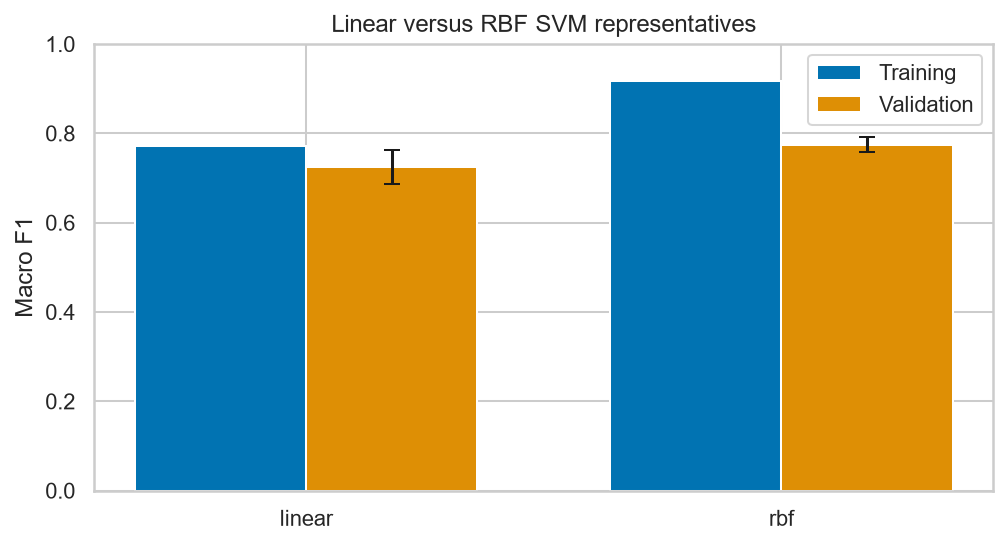

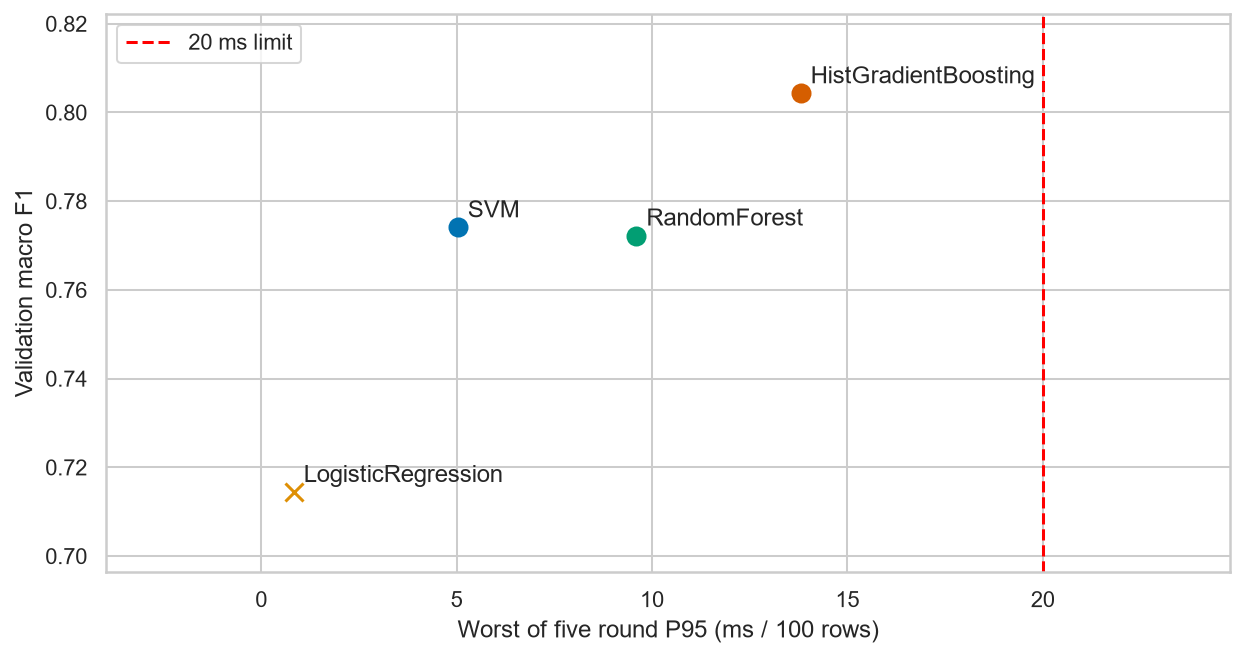

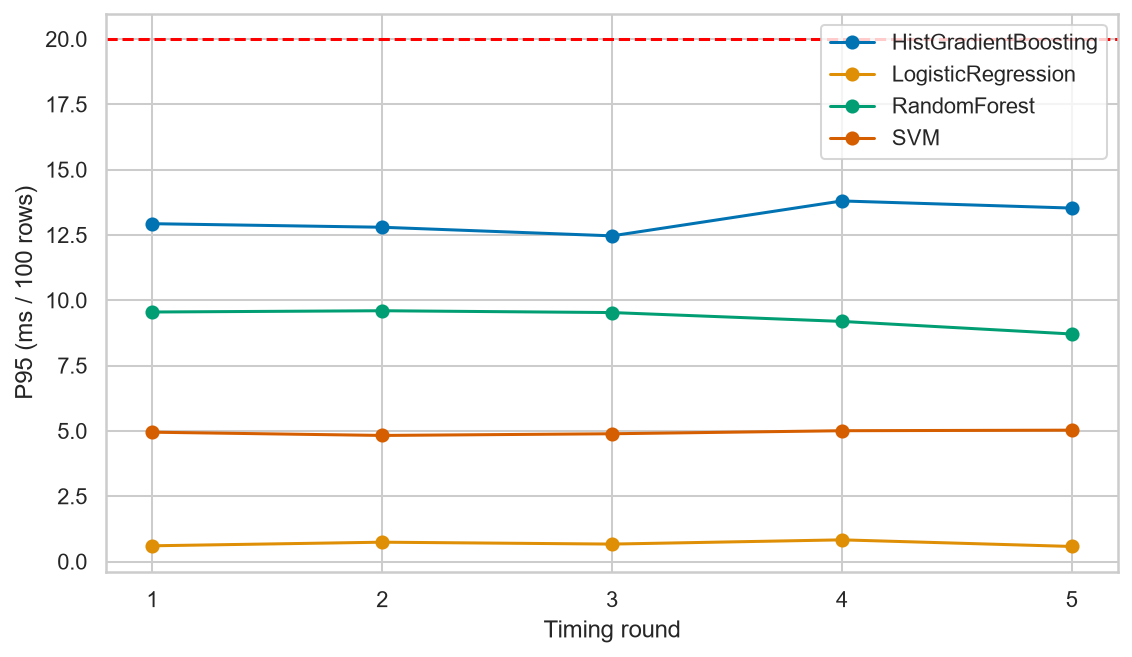

In [15]:
kw=pd.DataFrame(kernel_winners)
fig,ax=plt.subplots(figsize=(8,4))
pos=np.arange(2)
ax.bar(pos-.18,kw.train_macro_f1,.36,label='Training')
ax.bar(pos+.18,kw.validation_macro_f1,.36,yerr=kw.validation_macro_f1_std,capsize=4,label='Validation')
ax.set(xticks=pos,xticklabels=kw.kernel,ylabel='Macro F1',ylim=(0,1),title='Linear versus RBF SVM representatives')
ax.legend();figure(fig,'01_linear_rbf.png')
fig,ax=plt.subplots(figsize=(10,5))
for _,row in comparison.iterrows():
    ax.scatter(row.worst_round_p95_ms,row.validation_macro_f1,s=80,marker='o' if row.stable_feasible else 'x')
    ax.annotate(row.family,(row.worst_round_p95_ms,row.validation_macro_f1),xytext=(5,5),textcoords='offset points')
ax.axvline(20,color='red',linestyle='--',label='20 ms limit')
ax.margins(x=.25,y=.2)
ax.set(xlabel='Worst of five round P95 (ms / 100 rows)',ylabel='Validation macro F1')
ax.legend();figure(fig,'02_stable_quality_latency.png')
raw_timing=pd.DataFrame(latency_rows)
chosen_ids=comparison.candidate_id.tolist()
round_summary=raw_timing[raw_timing.candidate_id.isin(chosen_ids)].groupby(['family','candidate_id','round']).predict_100_ms.agg(
    median='median',p95=lambda a:np.quantile(a,.95)).reset_index()
table(round_summary,'representative_timing_rounds.csv')
fig,ax=plt.subplots(figsize=(9,5))
for family,group in round_summary.groupby('family'):
    ax.plot(group['round'],group.p95,marker='o',label=family)
ax.axhline(20,color='red',linestyle='--')
ax.set(xlabel='Timing round',ylabel='P95 (ms / 100 rows)',xticks=range(1,6))
ax.legend();figure(fig,'03_timing_stability.png')


## 5. ROC and PR

Use each validation fold's decision_function scores to calculate class ROC AUC and average precision, then average across folds. Scores are not probabilities; AP is not trapezoidal PR area. SVC trains internally using one-versus-one classifiers.

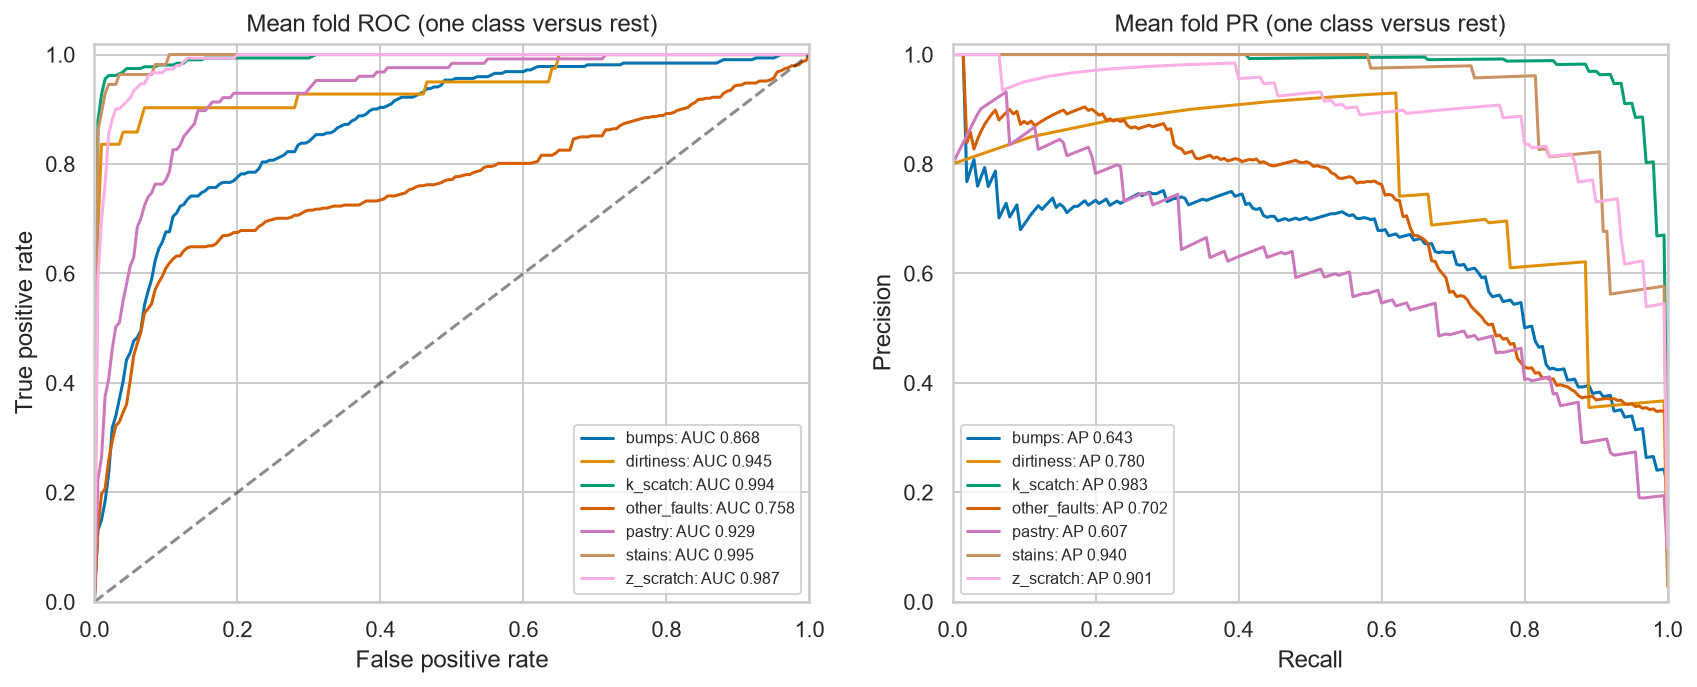

,roc_auc_mean,roc_auc_sd,ap_mean,ap_sd,prevalence
bumps,0.8679,0.0294,0.6434,0.1017,0.2068
dirtiness,0.9449,0.0833,0.7804,0.2266,0.0283
k_scatch,0.9941,0.0047,0.9825,0.0125,0.2017
other_faults,0.7581,0.0296,0.7022,0.0132,0.3466
pastry,0.9293,0.0235,0.6075,0.1234,0.0812
stains,0.9949,0.0051,0.9400,0.0410,0.0374
z_scratch,0.9871,0.0078,0.9007,0.0563,0.0979


In [16]:
curve_metrics=[]
score_frames=[]
roc_points=[]
pr_points=[]
roc_grid=np.linspace(0,1,201)
recall_grid=np.linspace(0,1,201)
svm_params=representative_params['SVM']
for fold,(fit,val) in enumerate(folds,1):
    pipe=make_pipe('SVM',svm_params)
    with threadpool_limits(limits=1):
        pipe.fit(X.iloc[fit],y.iloc[fit]);check_preprocessing(pipe,X.iloc[fit])
        scores=pipe.decision_function(X.iloc[val])
    assert list(pipe.classes_)==classes and scores.shape==(len(val),len(classes))
    sf=pd.DataFrame(scores,columns=classes)
    sf.insert(0,'row_id',X.index[val]);sf.insert(1,'fold',fold);sf.insert(2,'truth',y.iloc[val].to_numpy())
    score_frames.append(sf)
    for j,label in enumerate(classes):
        truth=(y.iloc[val].to_numpy()==label).astype(int)
        fpr,tpr,_=roc_curve(truth,scores[:,j])
        precision,recall,_=precision_recall_curve(truth,scores[:,j])
        interp_tpr=np.interp(roc_grid,fpr,tpr);interp_tpr[0]=0;interp_tpr[-1]=1
        interp_precision=np.interp(recall_grid,recall[::-1],precision[::-1])
        curve_metrics.append({'fold':fold,'class':label,'roc_auc':roc_auc_score(truth,scores[:,j]),
            'average_precision':average_precision_score(truth,scores[:,j]),'prevalence':float(truth.mean())})
        roc_points.extend({'fold':fold,'class':label,'fpr':float(x),'tpr':float(v)} for x,v in zip(roc_grid,interp_tpr))
        pr_points.extend({'fold':fold,'class':label,'recall':float(x),'precision':float(v)} for x,v in zip(recall_grid,interp_precision))
table(pd.concat(score_frames,ignore_index=True),'svm_validation_decision_scores.csv')
table(pd.DataFrame(curve_metrics),'svm_curve_metrics.csv')
table(pd.DataFrame(roc_points),'roc_interpolated.csv')
table(pd.DataFrame(pr_points),'pr_interpolated.csv')
curve_summary=pd.DataFrame(curve_metrics).groupby('class').agg(roc_auc_mean=('roc_auc','mean'),roc_auc_sd=('roc_auc','std'),
    ap_mean=('average_precision','mean'),ap_sd=('average_precision','std'),prevalence=('prevalence','mean'))
table(curve_summary.rename_axis('class').reset_index(),'svm_curve_summary.csv')
fig,axes=plt.subplots(1,2,figsize=(14,5))
for label in classes:
    rc=pd.DataFrame(roc_points).query('`class` == @label').groupby('fpr').tpr.mean()
    pr=pd.DataFrame(pr_points).query('`class` == @label').groupby('recall').precision.mean()
    axes[0].plot(rc.index,rc.values,label=f'{label}: AUC {curve_summary.loc[label,"roc_auc_mean"]:.3f}')
    axes[1].plot(pr.index,pr.values,label=f'{label}: AP {curve_summary.loc[label,"ap_mean"]:.3f}')
axes[0].plot([0,1],[0,1],'k--',alpha=.5)
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Mean fold ROC (one class versus rest)')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Mean fold PR (one class versus rest)')
for ax in axes:ax.legend(fontsize=8);ax.set_xlim(0,1);ax.set_ylim(0,1.02)
figure(fig,'04_svm_roc_pr.png')
display(curve_summary)


## 6. Permutation importance

Shuffle each feature five times within each of the five validation folds and record the decrease in macro F1. Correlated features can substitute for each other. Importance is not causal and is not used to select features again.

Permutation importance: SVM fold 1 /5
Permutation importance: SVM fold 2 /5
Permutation importance: SVM fold 3 /5
Permutation importance: SVM fold 4 /5
Permutation importance: SVM fold 5 /5
Permutation importance: LogisticRegression fold 1 /5
Permutation importance: LogisticRegression fold 2 /5
Permutation importance: LogisticRegression fold 3 /5
Permutation importance: LogisticRegression fold 4 /5
Permutation importance: LogisticRegression fold 5 /5
Permutation importance: RandomForest fold 1 /5
Permutation importance: RandomForest fold 2 /5
Permutation importance: RandomForest fold 3 /5
Permutation importance: RandomForest fold 4 /5
Permutation importance: RandomForest fold 5 /5
Permutation importance: HistGradientBoosting fold 1 /5
Permutation importance: HistGradientBoosting fold 2 /5
Permutation importance: HistGradientBoosting fold 3 /5
Permutation importance: HistGradientBoosting fold 4 /5
Permutation importance: HistGradientBoosting fold 5 /5


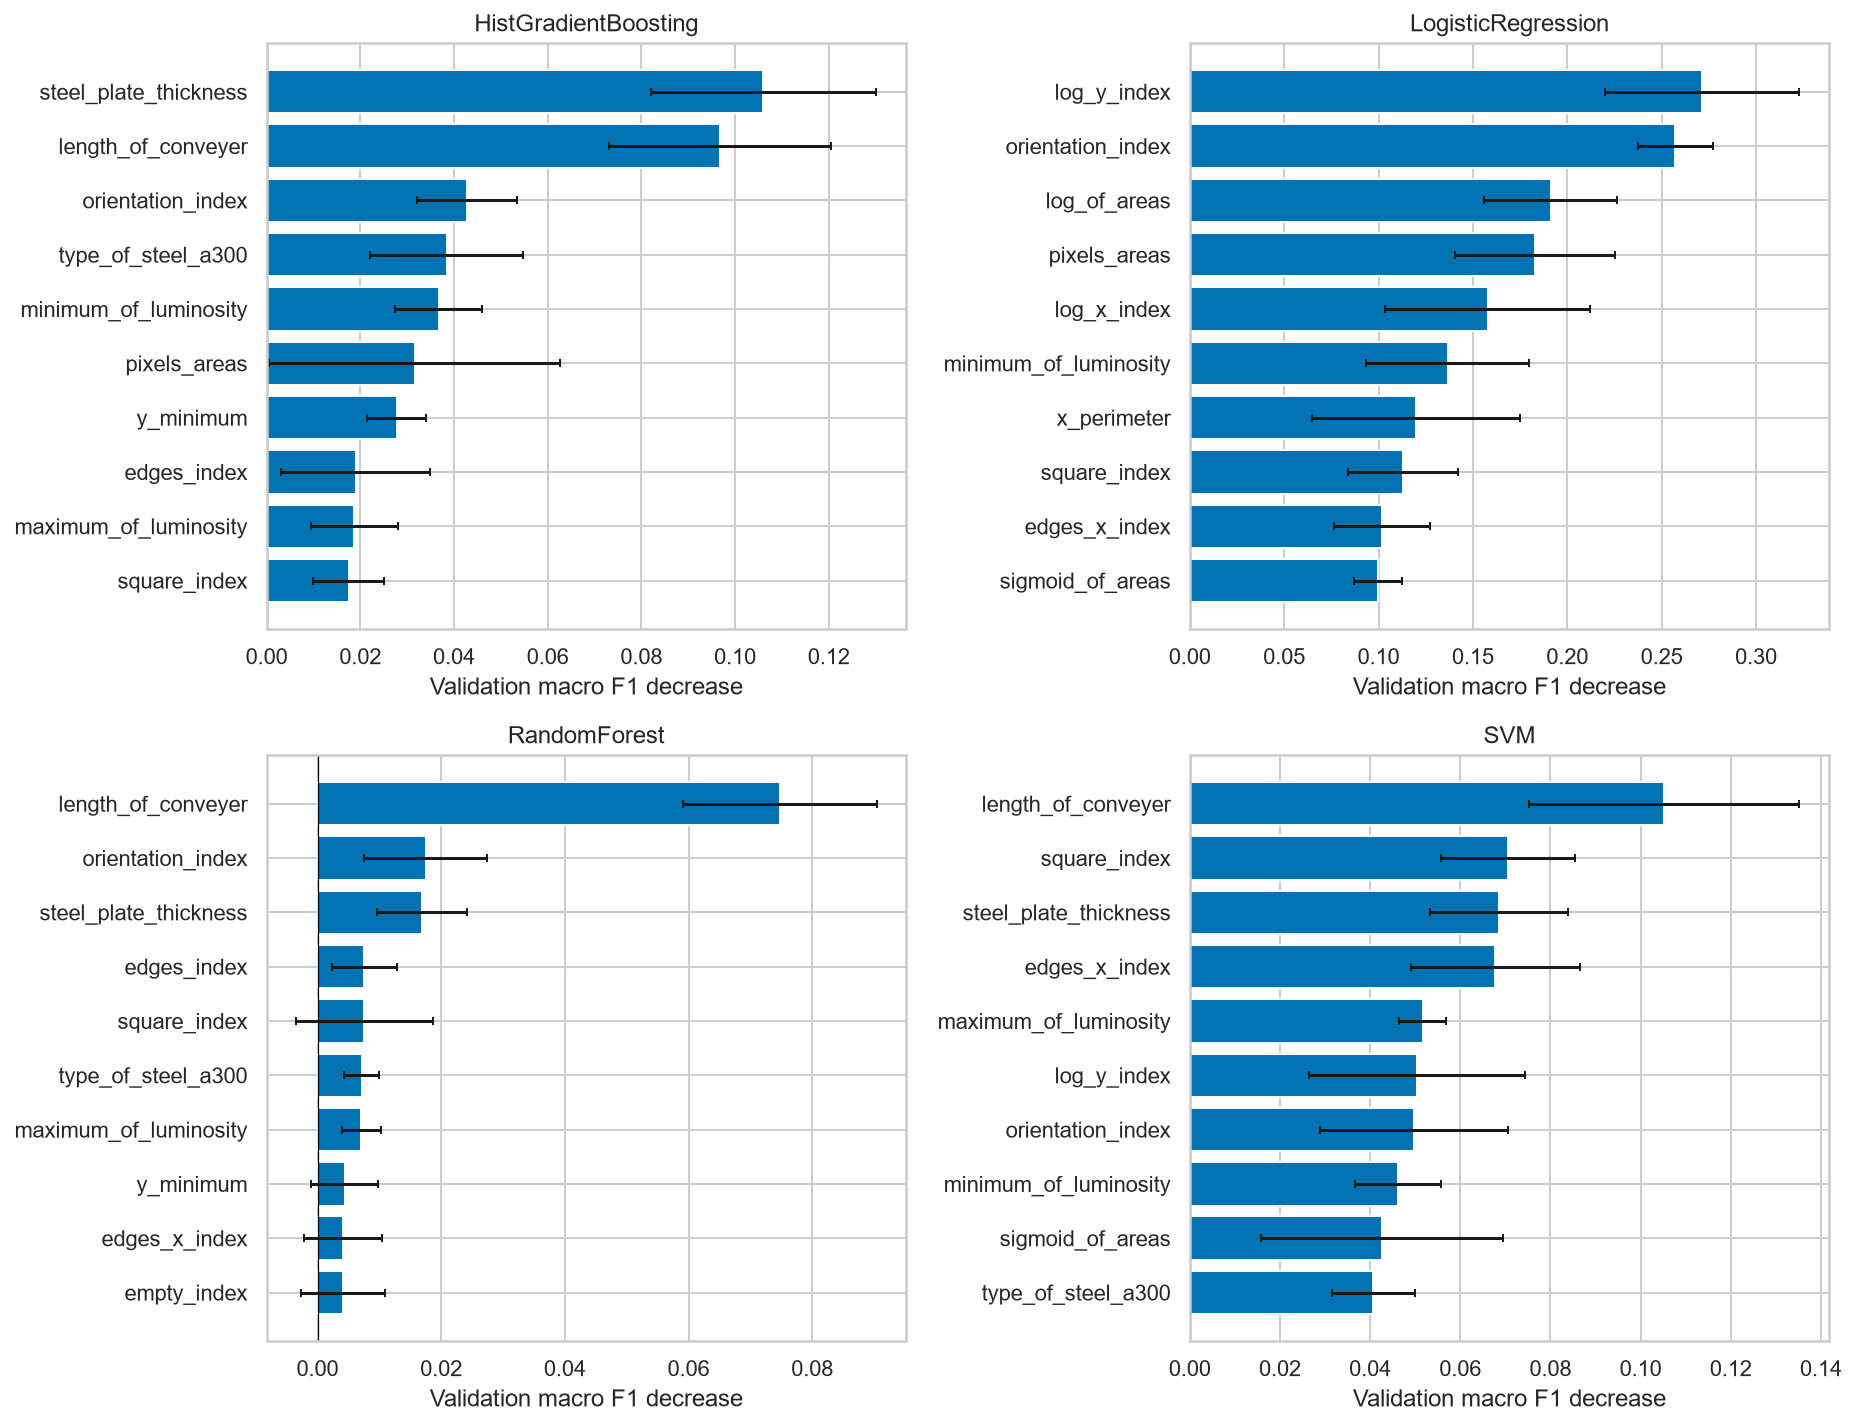

In [17]:
importance_rows=[]
fold_rechecks=[]
for _,row in comparison.iterrows():
    family=row.family
    for fold,(fit,val) in enumerate(folds,1):
        pipe=make_pipe(family,representative_params[family])
        with threadpool_limits(limits=1):
            pipe.fit(X.iloc[fit],y.iloc[fit]);check_preprocessing(pipe,X.iloc[fit])
            pred=pipe.predict(X.iloc[val])
            val_score=f1_score(y.iloc[val],pred,average='macro')
            imp=permutation_importance(pipe,X.iloc[val],y.iloc[val],scoring='f1_macro',
                n_repeats=PERMUTATION_REPEATS,random_state=SEED+fold,n_jobs=1)
        fold_rechecks.append({'family':family,'fold':fold,'validation_macro_f1':val_score})
        for feature,values in zip(X.columns,imp.importances):
            importance_rows.extend({'family':family,'fold':fold,'feature':feature,'repeat':i+1,
                'macro_f1_decrease':float(v)} for i,v in enumerate(values))
        table(pd.DataFrame(importance_rows),'permutation_importance_raw.csv')
        print('Permutation importance:',family,'fold',fold,'/5',flush=True)
importance_raw=pd.DataFrame(importance_rows)
importance_fold=importance_raw.groupby(['family','feature','fold']).macro_f1_decrease.mean().reset_index()
importance_summary=importance_fold.groupby(['family','feature']).macro_f1_decrease.agg(mean='mean',fold_sd='std').reset_index()
table(importance_summary,'permutation_importance_summary.csv')
table(pd.DataFrame(fold_rechecks),'representative_cv_recheck.csv')
for _,row in comparison.iterrows():
    actual=pd.DataFrame(fold_rechecks).query('family == @row.family').validation_macro_f1.mean()
    np.testing.assert_allclose(actual,row.validation_macro_f1,rtol=1e-9,atol=1e-9)
fig,axes=plt.subplots(2,2,figsize=(13,10))
for ax,(family,group) in zip(axes.flat,importance_summary.groupby('family')):
    top=group.nlargest(10,'mean').sort_values('mean')
    ax.barh(top.feature,top['mean'],xerr=top.fold_sd,capsize=2)
    ax.axvline(0,color='black',linewidth=.6)
    ax.set(title=family,xlabel='Validation macro F1 decrease')
fig.tight_layout();figure(fig,'05_permutation_importance.png')


## 7. Learning curves and training cost

SVM uses Part A's saved nested subsets. Other models reuse Part A's curves from this reproduction. Internal validation data informed development, so the curves are diagnostic only. Full-fit timing is repeated five times; memory evidence is retained from Part A.

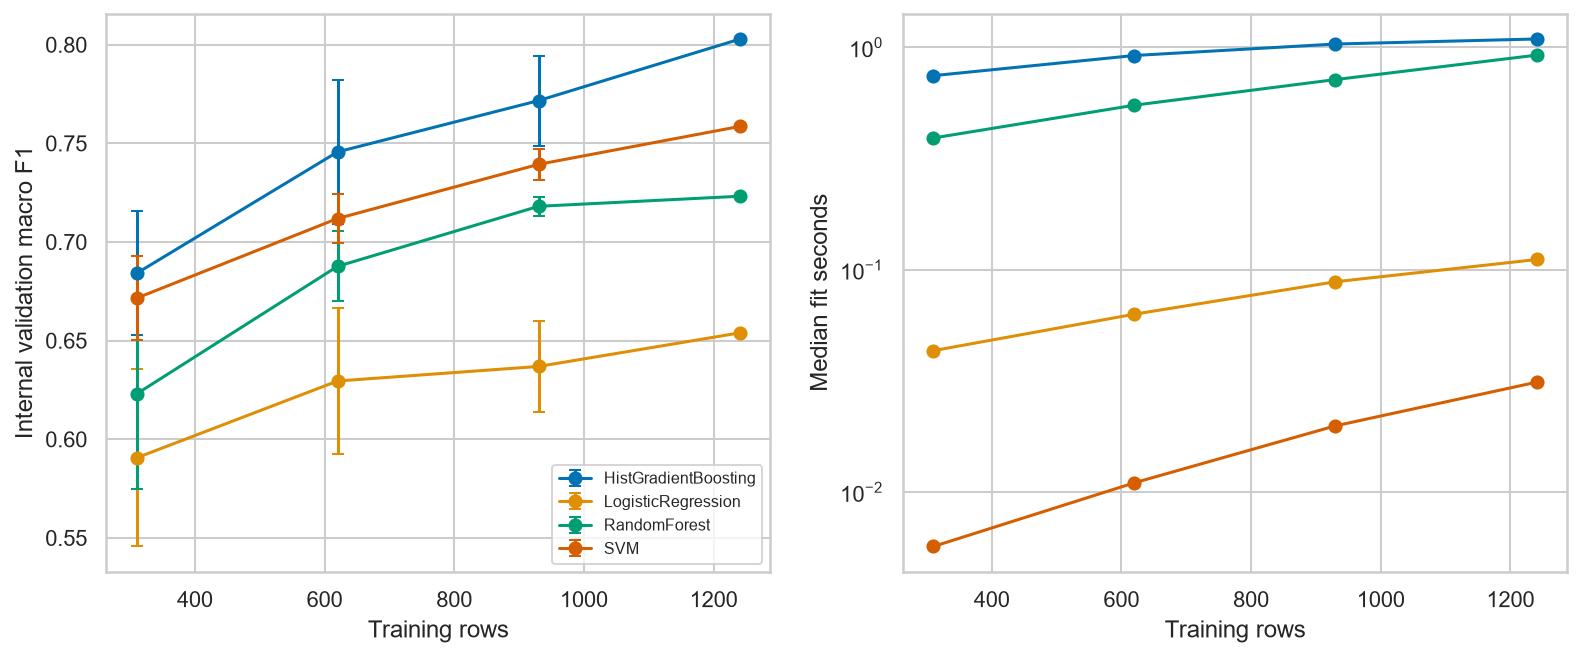

,family,fit_median_seconds,fit_q25_seconds,fit_q75_seconds,serialized_model_kib,worst_round_p95_ms
0,SVM,0.0447,0.0446,0.0450,272.4189,5.0275
1,LogisticRegression,0.0744,0.0742,0.0744,4.8135,0.8290
2,RandomForest,0.8250,0.8239,0.8341,8389.0254,9.5979
3,HistGradientBoosting,0.7638,0.7557,0.7711,1316.4150,13.8004


In [18]:
subsets=pd.read_csv(ORIGINAL/'learning_subsets.csv')
learning_ids=pd.read_csv(ORIGINAL/'learning_validation_rows.csv').row_id.to_numpy()
assert set(learning_ids)<=training_ids
svm_learning=[]
for (repeat,fraction),group in subsets.groupby(['repeat','fraction']):
    ids=group.row_id.to_numpy()
    assert not set(ids)&set(learning_ids) and set(ids)<=training_ids
    pipe=make_pipe('SVM',svm_params)
    with threadpool_limits(limits=1):
        t=perf_counter();pipe.fit(X.loc[ids],y.loc[ids]);seconds=perf_counter()-t
        check_preprocessing(pipe,X.loc[ids])
        train_pred=pipe.predict(X.loc[ids]);val_pred=pipe.predict(X.loc[learning_ids])
    svm_learning.append({'family':'SVM','repeat':repeat,'fraction':fraction,'train_rows':len(ids),
        'train_macro_f1':f1_score(y.loc[ids],train_pred,average='macro'),
        'validation_macro_f1':f1_score(y.loc[learning_ids],val_pred,average='macro'),'fit_seconds':seconds,'source':'supplement'})
table(pd.DataFrame(svm_learning),'svm_learning_curve_raw.csv')
old_learning=pd.read_csv(ORIGINAL/'learning_curve_raw.csv')
old_learning=old_learning[old_learning.family!='RBF_SVC'].copy();old_learning['source']='original_CW2'
learning=pd.concat([old_learning,pd.DataFrame(svm_learning)],ignore_index=True)
table(learning,'combined_learning_curves.csv')
fig,axes=plt.subplots(1,2,figsize=(13,5))
for family,group in learning.groupby('family'):
    summary=group.groupby('train_rows').agg(train=('train_macro_f1','mean'),val=('validation_macro_f1','mean'),sd=('validation_macro_f1','std'),seconds=('fit_seconds','median'))
    axes[0].errorbar(summary.index,summary.val,yerr=summary.sd,marker='o',capsize=3,label=family)
    axes[1].plot(summary.index,summary.seconds,marker='o',label=family)
axes[0].set(xlabel='Training rows',ylabel='Internal validation macro F1')
axes[1].set(xlabel='Training rows',ylabel='Median fit seconds',yscale='log')
axes[0].legend(fontsize=8)
figure(fig,'06_updated_learning_curves.png')
cost_rows=[]
fit_times=[]
for _,row in comparison.iterrows():
    times=[]
    for repeat in range(1,6):
        pipe=make_pipe(row.family,representative_params[row.family])
        with threadpool_limits(limits=1):
            t=perf_counter();pipe.fit(X,y);elapsed=perf_counter()-t
        times.append(elapsed);fit_times.append({'family':row.family,'repeat':repeat,'fit_seconds':elapsed})
    model_path=RUN/f'{row.family}_representative.joblib'
    joblib.dump(timed_models[row.candidate_id],model_path)
    cost_rows.append({'family':row.family,'fit_median_seconds':float(np.median(times)),
        'fit_q25_seconds':float(np.quantile(times,.25)),'fit_q75_seconds':float(np.quantile(times,.75)),
        'serialized_kib':model_path.stat().st_size/1024,'worst_round_p95_ms':row.worst_round_p95_ms})
table(pd.DataFrame(fit_times),'fit_timing_raw.csv')
table(pd.DataFrame(cost_rows),'updated_resource_comparison.csv')
display(pd.DataFrame(cost_rows))


## 8. Development checks

These checks cover the development experiments. Frozen holdout results follow in Part D.

In [19]:
checks={
    'development_rows_match_original':set(X.index)==training_ids,
    'no_holdout_rows_in_development':not bool(set(X.index)&excluded_ids),
    'both_kernels_compared':set(svm_results.kernel)=={'linear','rbf'},
    'every_candidate_accounted':len(rows)+len(failures)==len(params_by_id),
    'complete_candidates_have_five_folds':len(fold_rows)==5*len(rows),
    'every_oof_row_once':all(len(f)==1552 and f.row_id.is_unique for f in oof_frames),
    'all_four_families_compared':set(comparison.family)=={'SVM','LogisticRegression','RandomForest','HistGradientBoosting'},
    'each_timed_candidate_has_500_calls':all(len(g)==500 for _,g in pd.DataFrame(latency_rows).groupby('candidate_id')),
    'seven_class_curve_metrics':len(curve_metrics)==35,
    'importance_records_complete':len(importance_rows)==4*5*27*PERMUTATION_REPEATS,
    'svm_learning_fits_complete':len(svm_learning)==20,
    'test_predictions_not_written':not (RUN/'test_predictions.csv').exists(),
}
assert all(checks.values()),checks
save_json({'checks':checks,'passed':sum(checks.values()),'total':len(checks),'test_evaluations':0},'execution_verification.json')
original_hgb=old_comparison[old_comparison.family=='HistGradientBoosting'].iloc[0]
new_hgb=comparison[comparison.family=='HistGradientBoosting'].iloc[0]
summary=f'''# SVM development results

- Search: {len(rows)} completed configurations and {len(failures)} failures.
- Retained RBF SVM: validation macro F1 {svm_winner['validation_macro_f1']:.4f} ± {svm_winner['validation_macro_f1_std']:.4f}; minimum OOF recall {svm_winner['oof_min_class_recall']:.4f}.
- This reproduction: SVM passed {svm_winner['timing_rounds_passed']}/5 rounds; worst P95 {svm_winner['worst_round_p95_ms']:.3f} ms. Boosting passed {new_hgb.timing_rounds_passed}/5; worst P95 {new_hgb.worst_round_p95_ms:.3f} ms.
- This run's automatic ranking: {selected['family']}. This is descriptive, not the final engineering choice. The preferred development candidate remains the frozen RBF SVM.

The historical timing evidence is in Part C; holdout results are in Part D. Search budgets differ, and adaptive CV can be optimistic. Timing includes preprocessing but excludes acquisition and feature extraction. No timing cause was established.
'''
(RUN/'supplement_summary.md').write_text(summary,encoding='utf-8')
display(Markdown(summary))
save_json({'finished_at_utc':datetime.now(timezone.utc).isoformat(),'test_evaluations':0},'COMPLETED.json')
(ROOT/'results'/'latest_run.txt').write_text(RUN.name,encoding='utf-8')
print(f'Checks passed: {sum(checks.values())}/{len(checks)}. Results: {RUN}')


# SVM development results

- Search: 53 completed configurations and 6 failures.
- Retained RBF SVM: validation macro F1 0.7741 ± 0.0169; minimum OOF recall 0.6134.
- This reproduction: SVM passed 5/5 rounds; worst P95 5.027 ms. Boosting passed 5/5; worst P95 13.800 ms.
- This run's automatic ranking: HistGradientBoosting. This is descriptive, not the final engineering choice. The preferred development candidate remains the frozen RBF SVM.

The historical timing evidence is in Part C; holdout results are in Part D. Search budgets differ, and adaptive CV can be optimistic. Timing includes preprocessing but excludes acquisition and feature extraction. No timing cause was established.


Checks passed: 12/12. Results: C:\Users\lei\Documents\ChatGPT\钢铁数据集\CW2_integrated_20261114\supplement\results\20261115_140733_507021


## Part C — Selection and timing evidence

Across the two historical experiments, SVM passed 10/10 timing rounds with worst P95 8.122 ms; boosting passed 8/10 with worst P95 23.563 ms. Boosting had higher validation F1 (0.8043 versus 0.7741), while SVM had more timing headroom.

The corrected historical run automatically ranked boosting first. The later SVM preference was an engineering judgement based on both runs, not a preregistered ten-round rule. New timing results do not change this frozen choice. The causes of timing variation were not measured.

In [23]:

ARCHIVE=INTEGRATED_ROOT/'archive/supplement_corrected'
historical=pd.read_csv(ARCHIVE/'updated_model_comparison.csv')
for family in ['SVM','LogisticRegression','RandomForest','HistGradientBoosting']:
    old=historical.set_index('family').loc[family]
    now=comparison.set_index('family').loc[family]
    np.testing.assert_allclose([now.train_macro_f1,now.validation_macro_f1,now.oof_min_class_recall],
        [old.train_macro_f1,old.validation_macro_f1,old.oof_min_class_recall],rtol=0,atol=1e-10)
history=pd.read_csv(ARCHIVE/'cross_run_timing_audit.csv')
table(history,'historical_cross_run_timing.csv')
display(history[['run','family','rounds_passed','total_rounds','worst_round_p95_ms']])
print('Current reproduction timing (separate from historical selection):')
display(comparison[['family','validation_macro_f1','oof_min_class_recall','worst_round_p95_ms','timing_rounds_passed']])

frozen=joblib.load(INTEGRATED_ROOT/'archive/frozen_RBF_SVM.joblib')
rep=timed_models['SVM_049']
assert frozen[-1].get_params()==rep[-1].get_params()
np.testing.assert_allclose(frozen[-1].support_vectors_,rep[-1].support_vectors_,rtol=0,atol=1e-12)
np.testing.assert_allclose(frozen[-1].dual_coef_,rep[-1].dual_coef_,rtol=0,atol=1e-12)
np.testing.assert_array_equal(frozen.classes_,rep.classes_)
assert set(frozen.classes_)==set(classes)
assert not (BASE_RUN_DIR/'test_predictions.csv').exists()
SUPPLEMENT_RUN=RUN
save_json({'cv_reproduced':True,'original_candidates':48,'svm_complete':len(rows),
 'svm_failed':len(failures),'fixed_model_matches_reproduction':True,
 'historical_decision_preserved':True,'holdout_predictions_so_far':0},'integration_checks_before_test.json')


,run,family,rounds_passed,total_rounds,worst_round_p95_ms
0,20261104_153815_292759,SVM,5,5,5.0546
1,20261104_153815_292759,LogisticRegression,5,5,0.5823
2,20261104_153815_292759,RandomForest,5,5,17.0487
3,20261104_153815_292759,HistGradientBoosting,3,5,23.5632
4,20261104_154236_767611,SVM,5,5,8.1223
5,20261104_154236_767611,LogisticRegression,5,5,1.3342
6,20261104_154236_767611,RandomForest,5,5,15.8505
7,20261104_154236_767611,HistGradientBoosting,5,5,18.5465


Current reproduction timing (separate from historical selection):


,family,validation_macro_f1,oof_min_class_recall,worst_round_p95_ms,timing_rounds_passed
0,SVM,0.7741,0.6134,5.0275,5
1,LogisticRegression,0.7144,0.5227,0.8290,5
2,RandomForest,0.7722,0.6097,9.5979,5
3,HistGradientBoosting,0.8043,0.6349,13.8004,5


## Part D — Frozen SVM holdout evaluation

All metrics use the same saved predictions from the frozen model. Reruns check the model, dataset and row hashes before reusing that record. No retuning or model switching follows the evaluation.

The 389 rows were already exposed in CW1 and original CW2. This holdout is not a new independent test. Wilson 95% intervals describe recall uncertainty; they do not turn a failed point-estimate check into a pass.

Reusing the single frozen holdout prediction record; no new holdout prediction.


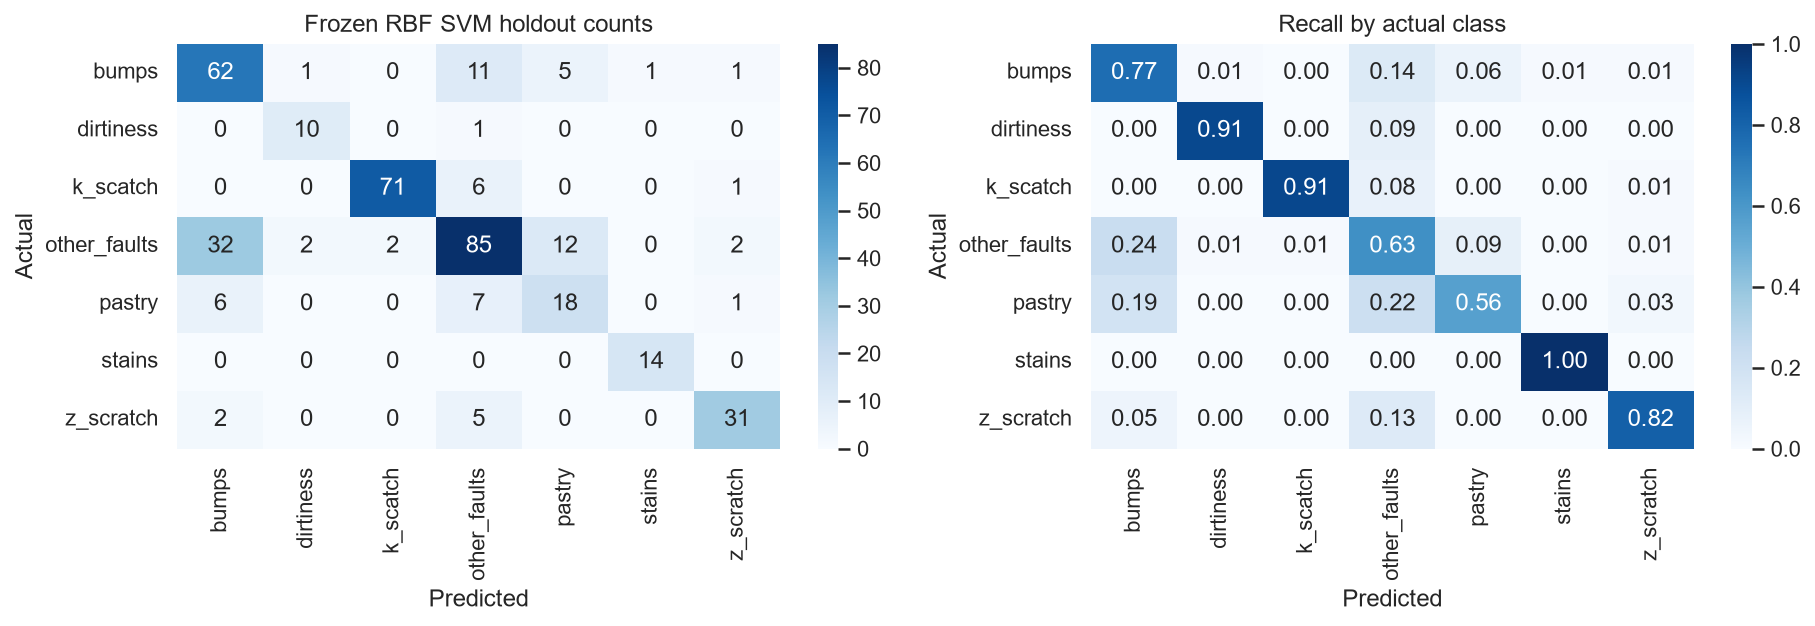

family                                                                   SVM
params                     {'kernel': 'rbf', 'C': 33.33333333333333, 'gam...
model_sha256           5673d3c6d259085c8546e5f0030ee69513ba5bc6d52e93...
dataset_sha256         9e9bfebd2ea8bf84f5264325fadace2194387991183cb2...
test_row_ids_sha256    610d3311372da8e34bea0663ad1b54c7092101c902af83...
predictions_sha256     b99a084a59cd1ef09783a34625ae5d2119a5c5cc354a73...
test_evaluation_count                                                                1
evaluated_at_utc                                 2026-11-14T14:14:20.775991+00:00
holdout_previously_used_in_cw1                                                           True
holdout_previously_used_in_original_cw2                                                          True
independent_external_test                                                             False
retuned_after_test                                                              False
rows       

,precision,recall,f1-score,rows,recall_wilson95_low,recall_wilson95_high,recall_constraint_pass
bumps,0.6078,0.7654,0.6776,81.0,0.6625,0.8444,True
dirtiness,0.7692,0.9091,0.8333,11.0,0.6226,0.9838,True
k_scatch,0.9726,0.9103,0.9404,78.0,0.8262,0.9558,True
other_faults,0.7391,0.6296,0.6800,135.0,0.5456,0.7064,True
pastry,0.5143,0.5625,0.5373,32.0,0.3933,0.7183,False
stains,0.9333,1.0000,0.9655,14.0,0.7847,1.0000,True
z_scratch,0.8611,0.8158,0.8378,38.0,0.6658,0.9078,True


All-class recall threshold met: False
Model and parameters remain unchanged regardless of the holdout result.


In [21]:
from sklearn.metrics import confusion_matrix
TEST_DIR=INTEGRATED_ROOT/'final_test'
model_path=INTEGRATED_ROOT/'archive/frozen_RBF_SVM.joblib'
model_hash=hashlib.sha256(model_path.read_bytes()).hexdigest()
assert model_hash==FROZEN_DECISION['model_sha256']
dataset_hash=hashlib.sha256(DATA.read_bytes()).hexdigest()
assert dataset_hash==EXPECTED
test_ids=pd.read_csv(BASE_RUN_DIR/'split_membership.csv')
test_ids=test_ids.loc[test_ids.split=='test','row_id'].to_numpy()
assert len(test_ids)==389 and len(set(test_ids))==389
assert not set(test_ids)&training_ids
test_rows=pd.read_csv(DATA).iloc[test_ids]
test_X=test_rows.drop(columns='fault_type')
test_y=test_rows.fault_type
row_hash=hashlib.sha256(test_ids.astype('<i8').tobytes()).hexdigest()
test_record=TEST_DIR/'test_metrics.json'
if test_record.exists():
    test_metrics=json.loads(test_record.read_text())
    assert test_metrics['model_sha256']==model_hash
    assert test_metrics['dataset_sha256']==dataset_hash
    assert test_metrics['test_row_ids_sha256']==row_hash
    pred_frame=pd.read_csv(TEST_DIR/'test_predictions.csv')
    assert hashlib.sha256((TEST_DIR/'test_predictions.csv').read_bytes()).hexdigest()==test_metrics['predictions_sha256']
    np.testing.assert_array_equal(pred_frame.row_id,test_ids)
    np.testing.assert_array_equal(pred_frame.truth,test_y.to_numpy())
    test_pred=pred_frame.prediction.to_numpy()
    print('Reusing the single frozen holdout prediction record; no new holdout prediction.')
else:
    assert not (TEST_DIR/'PREDICTION_STARTED.json').exists(), 'An interrupted test needs audit; do not silently predict twice.'
    (TEST_DIR/'PREDICTION_STARTED.json').write_text(json.dumps({'model_sha256':model_hash,'started_at_utc':datetime.now(timezone.utc).isoformat()}))
    with threadpool_limits(limits=1):

        test_pred=frozen.predict(test_X)
    pred_frame=pd.DataFrame({'row_id':test_ids,'truth':test_y.to_numpy(),'prediction':test_pred})
    pred_frame.to_csv(TEST_DIR/'test_predictions.csv',index=False,encoding='utf-8-sig')
    test_metrics={'family':'SVM','params':FROZEN_DECISION['params'],'model_sha256':model_hash,
       'dataset_sha256':dataset_hash,'test_row_ids_sha256':row_hash,
       'predictions_sha256':hashlib.sha256((TEST_DIR/'test_predictions.csv').read_bytes()).hexdigest(),
       'test_evaluation_count':1,'evaluated_at_utc':datetime.now(timezone.utc).isoformat(),
       'holdout_previously_used_in_cw1':True,'holdout_previously_used_in_original_cw2':True,
       'independent_external_test':False,'retuned_after_test':False,'rows':389}
test_classification=classification_report(test_y,test_pred,labels=classes,output_dict=True,zero_division=0)
test_detail=pd.DataFrame({c:test_classification[c] for c in classes}).T
test_cm=confusion_matrix(test_y,test_pred,labels=classes)
z=1.959963984540054
nn=test_detail.support.to_numpy();pp=test_detail.recall.to_numpy()
den=1+z*z/nn
center=(pp+z*z/(2*nn))/den
half=z*np.sqrt(pp*(1-pp)/nn+z*z/(4*nn*nn))/den
test_detail['recall_wilson95_low']=center-half
test_detail['recall_wilson95_high']=center+half
test_detail['recall_constraint_pass']=test_detail.recall>=MIN_RECALL
test_metrics.update({'test_accuracy':accuracy_score(test_y,test_pred),
 'test_macro_f1':f1_score(test_y,test_pred,average='macro'),
 'test_min_class_recall':float(test_detail.recall.min()),
 'test_recall_constraint_pass':bool(test_detail.recall.min()>=MIN_RECALL)})
test_record.write_text(json.dumps(test_metrics,indent=2),encoding='utf8')
test_detail.rename_axis('class').reset_index().to_csv(TEST_DIR/'test_classification_report.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(test_cm,index=classes,columns=classes).rename_axis('actual').reset_index().to_csv(TEST_DIR/'test_confusion_matrix.csv',index=False,encoding='utf-8-sig')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.heatmap(test_cm,annot=True,fmt='d',cmap='Blues',xticklabels=classes,yticklabels=classes,ax=axes[0])
sns.heatmap(test_cm/test_cm.sum(axis=1,keepdims=True),annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',xticklabels=classes,yticklabels=classes,ax=axes[1])
for ax,title in zip(axes,['Frozen RBF SVM holdout counts','Recall by actual class']):ax.set(xlabel='Predicted',ylabel='Actual',title=title)
fig.tight_layout();fig.savefig(TEST_DIR/'svm_test_confusion_matrix.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)
display(pd.Series(test_metrics))
display(test_detail)
print('All-class recall threshold met:',test_metrics['test_recall_constraint_pass'])
print('Model and parameters remain unchanged regardless of the holdout result.')


## Part E — Results and limitations

OOF recall describes development performance. Holdout recall is a separate check: pastry fails the 0.60 target, so immediate deployment is not recommended. No pipeline has been validated against all constraints.

In [22]:
metrics=json.loads((INTEGRATED_ROOT/'final_test/test_metrics.json').read_text())
final_summary=f"""# Final results

**RBF SVM is the preferred development candidate, not a deployment-ready solution.**

- Pipeline: median imputation, standardisation and RBF SVM; parameters {json.dumps(FROZEN_DECISION['params'])}.
- Validation macro F1: {svm_winner['validation_macro_f1']:.4f} ± {svm_winner['validation_macro_f1_std']:.4f}; minimum OOF recall: {svm_winner['oof_min_class_recall']:.4f}.
- Holdout: {metrics['rows']} rows, accuracy {metrics['test_accuracy']:.4f}, macro F1 {metrics['test_macro_f1']:.4f}.
- Pastry recall: 18/32 = {metrics['test_min_class_recall']:.4f}. The all-class 0.60 target failed; at least 20/32 correct predictions were required.

No pipeline has been validated against all constraints. Immediate deployment is not recommended. The model and threshold remain unchanged after testing. This holdout was previously exposed, so it is not new independent evidence. Later runs reuse the same hash-checked prediction record.
"""
(INTEGRATED_ROOT/'results_summary.md').write_text(final_summary,encoding='utf8')
display(Markdown(final_summary))
original_hashes=json.loads((INTEGRATED_ROOT/'qa/original_sha256.json').read_text())
assert all(Path(p).is_file() and hashlib.sha256(Path(p).read_bytes()).hexdigest()==h for p,h in original_hashes.items())
checks={'all_original_files_unchanged':True,'one_test_prediction_record':metrics['test_evaluation_count']==1,
 'prediction_rows':len(pd.read_csv(INTEGRATED_ROOT/'final_test/test_predictions.csv'))==389,
 'base_test_not_executed':not (BASE_RUN_DIR/'test_predictions.csv').exists(),
 'final_params_unchanged':metrics['model_sha256']==FROZEN_DECISION['model_sha256']}
assert all(checks.values()),checks
(INTEGRATED_ROOT/'qa/integrated_checks.json').write_text(json.dumps({'checks':checks,
 'base_run':str(BASE_RUN_DIR.relative_to(INTEGRATED_ROOT)),
 'supplement_run':str(SUPPLEMENT_RUN.relative_to(INTEGRATED_ROOT)),
 'original_file_count':len(original_hashes),'complete':True},indent=2),encoding='utf8')
print('Integration checks:',checks)


# Final results

**RBF SVM is the preferred development candidate, not a deployment-ready solution.**

- Pipeline: median imputation, standardisation and RBF SVM; parameters {"kernel": "rbf", "C": 33.33333333333333, "gamma": 0.03, "class_weight": "balanced"}.
- Validation macro F1: 0.7741 ± 0.0169; minimum OOF recall: 0.6134.
- Holdout: 389 rows, accuracy 0.7481, macro F1 0.7817.
- Pastry recall: 18/32 = 0.5625. The all-class 0.60 target failed; at least 20/32 correct predictions were required.

No pipeline has been validated against all constraints. Immediate deployment is not recommended. The model and threshold remain unchanged after testing. This holdout was previously exposed, so it is not new independent evidence. Later runs reuse the same hash-checked prediction record.


Integration checks: {'all_original_files_unchanged': True, 'one_test_prediction_record': True, 'prediction_rows': True, 'base_test_not_executed': True, 'final_params_unchanged': True}


## Further development

1. Analyse pastry errors using development OOF predictions, collect representative samples and review labels.
2. Compare targeted class weights and nearby C/gamma values within development CV; check precision, recall, macro F1 and timing together.
3. Freeze a revised pipeline and evaluate on new, unexamined data, preferably from different batches, with timing repeated on target hardware.

## Team contribution

| Member | Name | Student ID | Responsibility |
|---|---|---|---|
| A | Xianjie Zhang | 3271422Z | Baseline/SVM review and integration; SVM recommendation. |
| B | Zhuo Liu | 3264500L | Random forest review, comparison and presentation integration. |
| C | Yaotian Lei | 3191229L | Boosting, learning curves, overfitting and trade-offs. |
| D | Sun Peng | 3246696S | Data, validation, experimental design and reproducibility. |
| E | Tao Jin | 3251660J | Timing and cost review; final frozen SVM evaluation. |

**AI tools used and what for**

OpenAI Codex assisted with code generation and debugging, notebook integration, hash and metric checks, and frozen SVM evaluation.